# Analisis Pertumbuhan dan Location Quotient (LQ) Kegiatan Usaha Surabaya

Notebook final untuk menyajikan hasil analisis kegiatan usaha Kota Surabaya periode 2021-2025 sebagai dasar penyusunan artikel jurnal.

## 1. Pendahuluan dan tujuan

Notebook ini merangkum analisis deskriptif, pertumbuhan, LQ, peta spasial, serta kombinasi LQ dan CAGR yang telah tersedia. Perhitungan final dibaca dari berkas pada `output_jurnal`; cleaning dan perhitungan analisis tidak diulang. Notebook `profiling_data.ipynb` tetap menjadi arsip proses profiling, cleaning, dan analisis terdahulu.

Jumlah kota adalah `Id Proyek` unik di dalam tiap tahun. ID yang muncul pada beberapa tahun dihitung pada setiap tahun kemunculannya. Agregat sektor dan kecamatan dapat menghitung proyek lebih dari sekali jika proyek memiliki beberapa KBLI atau lokasi.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import HTML, IFrame, Image, Markdown, display

candidate_bases = [Path.cwd(), *Path.cwd().parents]
candidates = [*candidate_bases, *(base / 'Project_Akhir' for base in candidate_bases)]
PROJECT_DIR = next(
    (path for path in candidates if (path / 'output_jurnal' / 'Validasi_akhir.csv').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Folder output_jurnal tidak ditemukan. Jalankan notebook dari folder proyek.')

OUTPUT_DIR = PROJECT_DIR / 'output_jurnal'
VISUAL_DIR = PROJECT_DIR / 'output_visualisasi'
DATA_PATH = PROJECT_DIR / 'output' / 'data_clean.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Dataset hasil cleaning tidak ditemukan: {DATA_PATH}')
data_clean = pd.read_csv(
    DATA_PATH,
    usecols=['Id Proyek', 'KBLI_2digit', 'kecamatan_usaha', 'Tahun'],
    dtype={'Id Proyek': 'string', 'KBLI_2digit': 'string'},
)
TABLES = {
    path.stem: pd.read_csv(path, dtype={'KBLI_2digit': 'string'})
    for path in OUTPUT_DIR.glob('*.csv')
}
required_tables = [
    'Tabel_01_jumlah_kegiatan_tahunan_kota',
    'Tabel_02_ringkasan_lima_sektor_tertinggi_terendah',
    'Tabel_03_ringkasan_lima_kecamatan_tertinggi_terendah',
    'Tabel_04_pertumbuhan_kegiatan_sektor',
    'Tabel_05_pertumbuhan_kegiatan_kecamatan',
    'Tabel_06_jumlah_kombinasi_kategori_LQ_tahunan',
    'Tabel_07_lima_sektor_rerata_LQ_tertinggi_tahunan',
    'Tabel_08_lima_kecamatan_LQ_tertinggi_sektor_terpilih',
    'Tabel_09_perubahan_rerata_LQ_per_sektor',
    'Tabel_10_analisis_gabungan_LQ_dan_CAGR',
    'Tabel_11_ringkasan_kategori_gabungan',
    'Tabel_12_sektor_menonjol_per_kategori',
    'Tabel_13_LQ_tertinggi_dan_jumlah_kegiatan_aktual',
    'Tabel_14_validasi_unit_hitung_kota_dan_agregat',
    'Tabel_15_validasi_duplikasi_dan_id_lintas_tahun',
    'Tabel_16_perbandingan_kategori_LQ_lama_dan_panel_lengkap',
    'Validasi_akhir',
    'Daftar_tabel_jurnal',
    'Daftar_visualisasi_jurnal',
]
missing_tables = [name for name in required_tables if name not in TABLES]
if missing_tables:
    raise FileNotFoundError(f'Tabel keluaran tidak ditemukan: {missing_tables}')

LQ_PATH = PROJECT_DIR / 'output' / 'hasil_lq_kecamatan_kbli.csv'
if not LQ_PATH.is_file():
    raise FileNotFoundError(f'Hasil LQ tersimpan tidak ditemukan: {LQ_PATH}')
lq_results = pd.read_csv(LQ_PATH, dtype={'KBLI_2digit': 'string'})

COLUMN_LABELS = {
    'KBLI_2digit': 'Kode KBLI 2 digit',
    'nama_kategori_kbli_2digit': 'Nama KBLI 2 digit',
    'kecamatan_usaha': 'Kecamatan',
    'Tahun': 'Tahun',
    'tahun': 'Tahun',
    'jumlah_baris': 'Jumlah baris',
    'jumlah_id_proyek_unik': 'Id Proyek unik',
    'jumlah_kegiatan_usaha': 'Jumlah kegiatan usaha',
    'jumlah_kegiatan_2021_2025_proyek_tahun': 'Jumlah proyek-tahun 2021-2025',
    'perubahan_yoy_jumlah': 'Perubahan absolut YoY',
    'pertumbuhan_yoy_persen': 'Pertumbuhan YoY (%)',
    'perubahan_kumulatif_2021_2025_jumlah': 'Perubahan kumulatif 2021-2025',
    'perubahan_kumulatif_2021_2025_persen': 'Perubahan kumulatif (%)',
    'jumlah_kegiatan_sektor_kota': 'Jumlah kegiatan sektor kota',
    'jumlah_kegiatan_sektor_kota_tahun': 'Jumlah kegiatan sektor kota',
    'total_kegiatan_sektor_kota_tahun': 'Jumlah kegiatan sektor kota',
    'jumlah_id_proyek_unik_sektor_kota': 'Id Proyek unik sektor kota',
    'jumlah_kecamatan_dengan_kegiatan': 'Kecamatan dengan kegiatan',
    'rata_rata_lq_31_kecamatan': 'Rerata LQ 31 kecamatan',
    'rata_rata_lq_2021_2025': 'Rerata LQ 2021-2025',
    'perubahan_rata_rata_lq_2021_2025': 'Perubahan rerata LQ',
    'jumlah_tahun_lq_tersedia': 'Tahun LQ tersedia',
    'LQ': 'Nilai LQ',
    'Kategori_LQ': 'Klasifikasi LQ',
    'kategori_gabungan': 'Kategori gabungan',
    'cagr_2021_2025_persen': 'CAGR 2021-2025 (%)',
    'jumlah_kelompok_kbli': 'Jumlah kelompok KBLI',
}
LQ_TABLE = 'Tabel_09_perubahan_rerata_LQ_per_sektor'

def format_number(value, digits=0):
    if pd.isna(value):
        return ''
    if digits == 0:
        return f'{int(round(value)):,}'.replace(',', '.')
    return f'{value:,.{digits}f}'.replace(',', '\\0').replace('.', ',').replace('\\0', '.')

def format_for_journal(frame, key=None):
    result = frame.copy()
    for column in result.select_dtypes(include='number').columns:
        lower = column.casefold()
        if lower in {
            'lq', 'rata_rata_lq_31_kecamatan', 'rata_rata_lq_2021_2025',
            'perubahan_rata_rata_lq_2021_2025',
        } or (key == LQ_TABLE and column in {'2021', '2022', '2023', '2024', '2025'}):
            digits = 3
        elif 'persen' in lower or 'cagr' in lower:
            digits = 2
        else:
            digits = 0 if (result[column].dropna() % 1 == 0).all() else 2
        result[column] = result[column].map(lambda value: format_number(value, digits))
    return result.rename(columns=COLUMN_LABELS)

def show_frame(title, frame, key=None):
    display(Markdown(f'#### {title}'))
    table_html = format_for_journal(frame, key).to_html(index=False, escape=True, border=0)
    display(HTML(
        '<div style="max-height:520px; overflow:auto; border:1px solid #ddd; padding:4px">'
        + table_html
        + '</div>'
    ))

def show_table(title, key):
    show_frame(title, TABLES[key], key)

def show_figure(title, filename):
    path = OUTPUT_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f'Grafik tidak ditemukan: {path}')
    display(Markdown(f'#### {title}'))
    display(Image(filename=str(path)))

def show_map_png(title, filename):
    path = VISUAL_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f'PNG peta tidak ditemukan: {path}')
    display(Markdown(f'#### {title}'))
    display(Image(filename=str(path)))

def show_map(title, filename):
    path = OUTPUT_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f'Peta tidak ditemukan: {path}')
    display(Markdown(f'#### {title}'))
    display(IFrame(src=path.resolve().as_uri(), width='100%', height=620))

dataset_summary = pd.DataFrame([{
    'Sumber': str(DATA_PATH.relative_to(PROJECT_DIR)),
    'Jumlah baris': len(data_clean),
    'Id Proyek unik seluruh periode': data_clean['Id Proyek'].nunique(),
    'Tahun tersedia': ', '.join(sorted(data_clean['Tahun'].astype(str).unique())),
}])
show_frame('Ringkasan dataset hasil cleaning', dataset_summary)
print(f'Sumber tabel dan grafik final: {OUTPUT_DIR}')

#### Ringkasan dataset hasil cleaning

Sumber,Jumlah baris,Id Proyek unik seluruh periode,Tahun tersedia
output\data_clean.csv,520.077,520.026,"2021, 2022, 2023, 2024, 2025"


Sumber tabel dan grafik final: C:\Users\MyPC One Pro K7-24\Documents\gaitsa's\Project_Akhir\Project_Akhir\output_jurnal


## 2. Dataset hasil cleaning dan validasi unit hitung

Tabel berikut memuat hitungan baris dibanding `Id Proyek` unik per tahun, audit duplikasi/keterulangan lintas tahun, serta perbandingan hitungan kota dan agregat kecamatan-KBLI. Perbedaan agregat tidak mengubah acuan jumlah proyek kota: gunakan hitungan unik langsung per tahun.

In [2]:
show_table('Tabel 1. Jumlah baris dan Id Proyek unik per tahun', 'Tabel_01_jumlah_kegiatan_tahunan_kota')
show_table('Tabel 14. Perbandingan unit hitung kota dan agregat kecamatan-KBLI', 'Tabel_14_validasi_unit_hitung_kota_dan_agregat')
show_table('Tabel 15. Audit duplikasi dan Id Proyek lintas tahun', 'Tabel_15_validasi_duplikasi_dan_id_lintas_tahun')
show_table('Tabel 16. Perbandingan klasifikasi LQ tersimpan dan panel lengkap', 'Tabel_16_perbandingan_kategori_LQ_lama_dan_panel_lengkap')
show_table('Ringkasan validasi akhir', 'Validasi_akhir')

#### Tabel 1. Jumlah baris dan Id Proyek unik per tahun

Tahun,Jumlah baris,Id Proyek unik,selisih_baris_dan_id_unik,Perubahan absolut YoY,Pertumbuhan YoY (%),Perubahan kumulatif 2021-2025,Perubahan kumulatif (%)
2.021,30.253,30.252,1,,,0,"0,00"
2.022,114.985,114.972,13,84.720,"280,05",84.720,"280,05"
2.023,129.057,129.053,4,14.081,"12,25",98.801,"326,59"
2.024,137.455,137.449,6,8.396,"6,51",107.197,"354,35"
2.025,108.327,108.324,3,-29.125,"-21,19",78.072,"258,07"


#### Tabel 14. Perbandingan unit hitung kota dan agregat kecamatan-KBLI

Tahun,id_proyek_unik_kota,jumlah_agregat_kecamatan_kbli,selisih_agregat_dan_id_kota,catatan_unit
2.021,30.252,30.252,0,Agregat kecamatan-KBLI dapat menghitung satu proyek lebih dari sekali; angka kota memakai Id Proyek unik langsung per tahun.
2.022,114.972,114.972,0,Agregat kecamatan-KBLI dapat menghitung satu proyek lebih dari sekali; angka kota memakai Id Proyek unik langsung per tahun.
2.023,129.053,129.053,0,Agregat kecamatan-KBLI dapat menghitung satu proyek lebih dari sekali; angka kota memakai Id Proyek unik langsung per tahun.
2.024,137.449,137.450,1,Agregat kecamatan-KBLI dapat menghitung satu proyek lebih dari sekali; angka kota memakai Id Proyek unik langsung per tahun.
2.025,108.324,108.324,0,Agregat kecamatan-KBLI dapat menghitung satu proyek lebih dari sekali; angka kota memakai Id Proyek unik langsung per tahun.


#### Tabel 15. Audit duplikasi dan Id Proyek lintas tahun

Tahun,Jumlah baris,Id Proyek unik,baris_berulang_dalam_kombinasi_id_tahun_kbli_kecamatan,id_dengan_lebih_dari_satu_kombinasi_kbli_kecamatan,kelebihan_kombinasi_kbli_kecamatan_dibanding_id,id_dengan_lebih_dari_satu_kbli,id_dengan_lebih_dari_satu_kecamatan,id_yang_muncul_pada_tahun_lain,jumlah_agregat_lq_kecamatan_kbli,selisih_agregat_lq_dan_id_kota
2.021,30.253,30.252,1,0,0,0,0,1,30.252,0
2.022,114.985,114.972,13,0,0,0,0,23,114.972,0
2.023,129.057,129.053,4,0,0,0,0,0,129.053,0
2.024,137.455,137.449,5,1,1,0,1,0,137.450,1
2.025,108.327,108.324,3,0,0,0,0,24,108.324,0


#### Tabel 16. Perbandingan klasifikasi LQ tersimpan dan panel lengkap

Tahun,jumlah_kombinasi_kecamatan_kbli_dianalisis,kombinasi_lq_nol_sektor_aktif,kombinasi_dengan_kegiatan,Basis (LQ > 1),Non-basis (LQ < 1),Setara dengan struktur kota (LQ = 1),LQ tidak tersedia,basis_lama,non_basis_lama,setara_lama,perubahan_basis_vs_hasil_lama,perubahan_non_basis_vs_hasil_lama,perubahan_setara_vs_hasil_lama
2.021,2.573,835,1.738,916,1.657,0,0,916,822,0,0,835,0
2.022,2.573,406,2.167,1.007,1.566,0,0,1.007,1.160,0,0,406,0
2.023,2.573,354,2.126,962,1.518,0,93,962,1.164,0,0,354,0
2.024,2.573,380,2.131,1.031,1.480,0,62,1.031,1.100,0,0,380,0
2.025,2.573,362,2.118,969,1.511,0,93,968,1.148,2,1,363,-2


#### Ringkasan validasi akhir

pemeriksaan,kriteria,hasil
Sumber kegiatan,output/data_clean.csv; tidak dilakukan cleaning ulang,520077
Tahun tersedia,2021-2025,"2021, 2022, 2023, 2024, 2025"
ID proyek kosong,0,0
Jumlah kecamatan data,31,31
Kesesuaian nama kecamatan GeoJSON,31/31,31/31
Cakupan data peta LQ,31 kecamatan menerima data,Lulus; nama dicocokkan setelah normalisasi
Cakupan data peta pertumbuhan,31 kecamatan menerima data,Lulus; nama dicocokkan setelah normalisasi
ID tercatat pada lebih dari satu tahun,Dihitung dari Id Proyek berbeda,24
ID lintas tahun terhitung pada hitungan tahunan,24,Ya; tiap ID dihitung satu kali di setiap tahun kemunculannya
ID unik lintas seluruh periode,Jumlah Id Proyek berbeda di 2021-2025,520026


## 3. Gambaran umum kegiatan usaha

Bagian ini merangkum jumlah tahunan proyek unik serta peringkat KBLI dan kecamatan selama periode. Ringkasan sektor dan kecamatan menjumlahkan proyek-tahun; satu proyek lintas tahun dapat terhitung pada beberapa tahun, dan proyek dengan lebih dari satu KBLI dapat muncul pada lebih dari satu kelompok sektor. Karena itu, total lintas sektor bukan jumlah proyek unik kota.

#### Tabel 2. Lima kelompok KBLI tertinggi dan terendah, 2021-2025

Peringkat,Kelompok,Kode KBLI 2 digit,Nama KBLI 2 digit,Jumlah proyek-tahun 2021-2025
1,Top 5,47,"Perdagangan Eceran, Bukan Mobil dan Sepeda Motor",121.802
2,Top 5,46,"Perdagangan Besar, Bukan Mobil dan Sepeda Motor",91.502
3,Top 5,10,Industri Makanan,58.602
4,Top 5,56,Penyediaan Makan Minum,55.066
5,Top 5,41,Konstruksi Gedung,14.797
1,Bottom 5,39,Aktivitas Remediasi dan Pengelolaan Sampah Lainnya,8
2,Bottom 5,88,Aktivitas Sosial Tanpa Akomodasi,15
3,Bottom 5,87,Aktivitas Sosial di Dalam Panti,16
4,Bottom 5,06,"Pertambangan Minyak Bumi, Gas Alam, dan Panas Bumi",29
5,Bottom 5,65,"Asuransi, Reasuransi, dan Dana Pensiun, Bukan Jaminan Sosial Wajib",59


#### Tabel 3. Lima kecamatan tertinggi dan terendah, 2021-2025

Peringkat,Kelompok,Kecamatan,Jumlah proyek-tahun 2021-2025
1,Top 5,Rungkut,30.012
2,Top 5,Tambaksari,28.204
3,Top 5,Gubeng,27.464
4,Top 5,Wonokromo,27.100
5,Top 5,Sukolilo,26.468
1,Bottom 5,Bulak,6.426
2,Bottom 5,Simokerto,9.338
3,Bottom 5,Pakal,10.877
4,Bottom 5,Asem Rowo,11.581
5,Bottom 5,Benowo,11.697


#### Gambar 1. Jumlah kegiatan usaha unik Kota Surabaya, 2021-2025

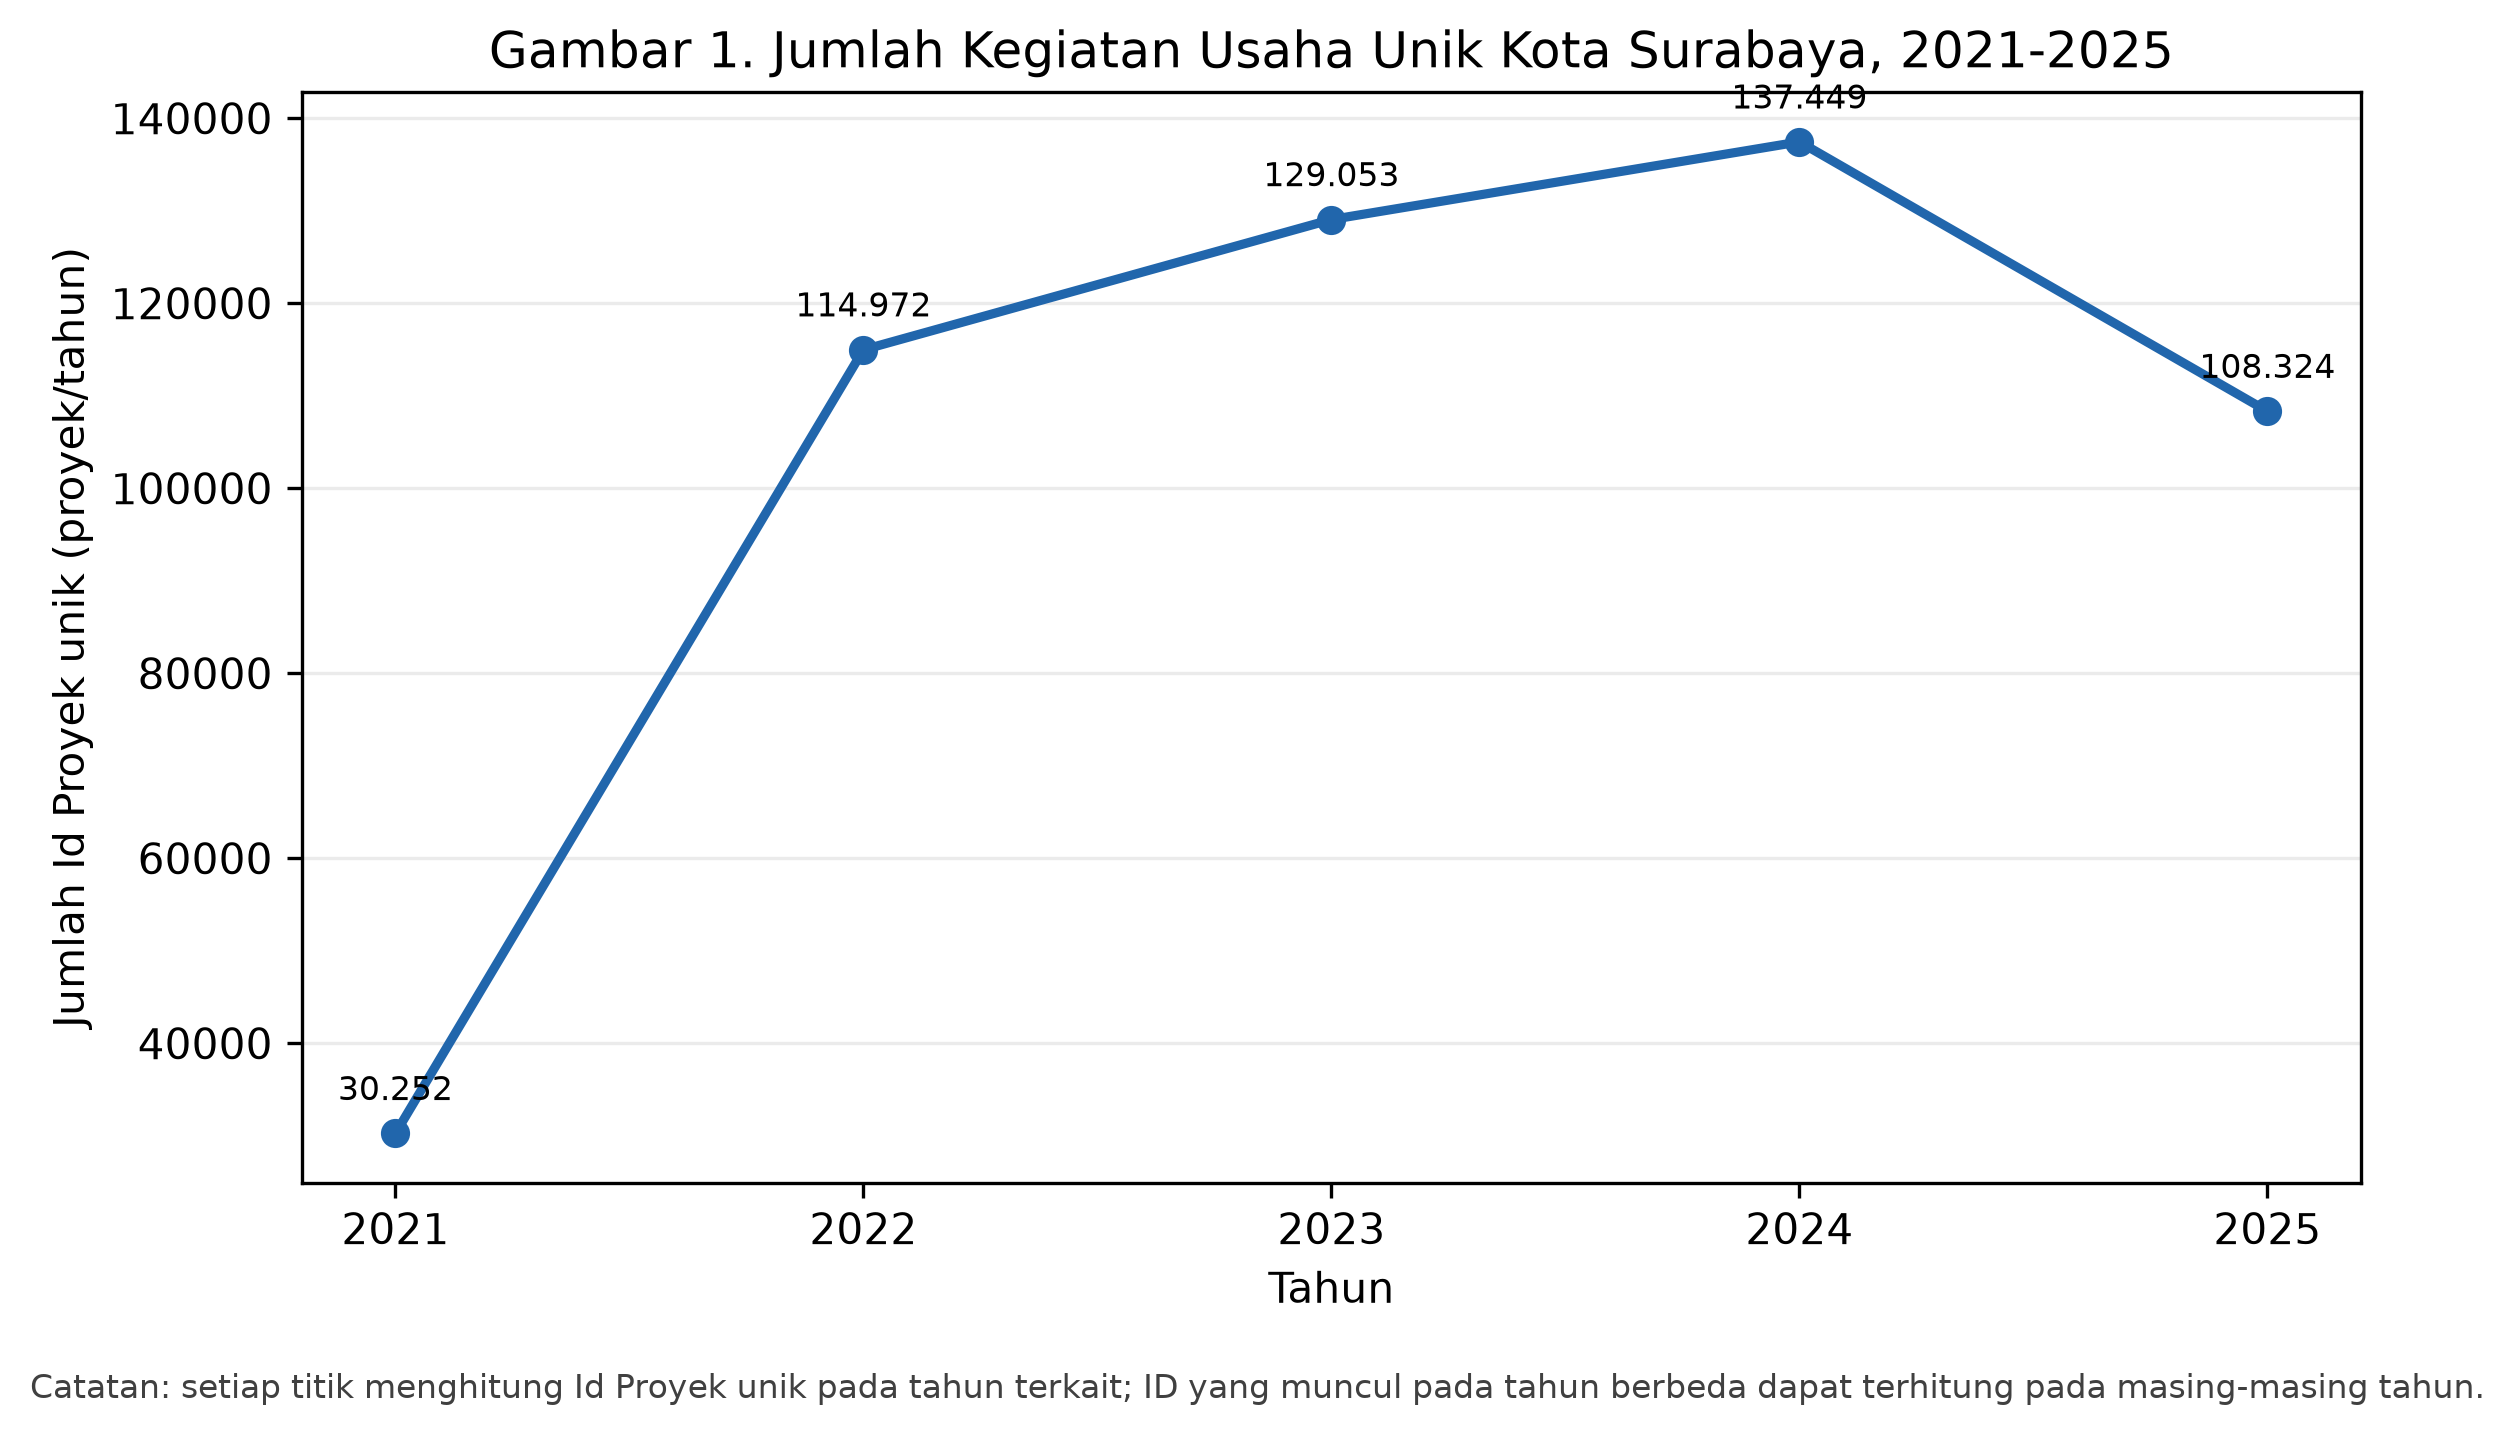

#### Gambar 2. Lima kelompok KBLI tertinggi dan terendah menurut proyek-tahun

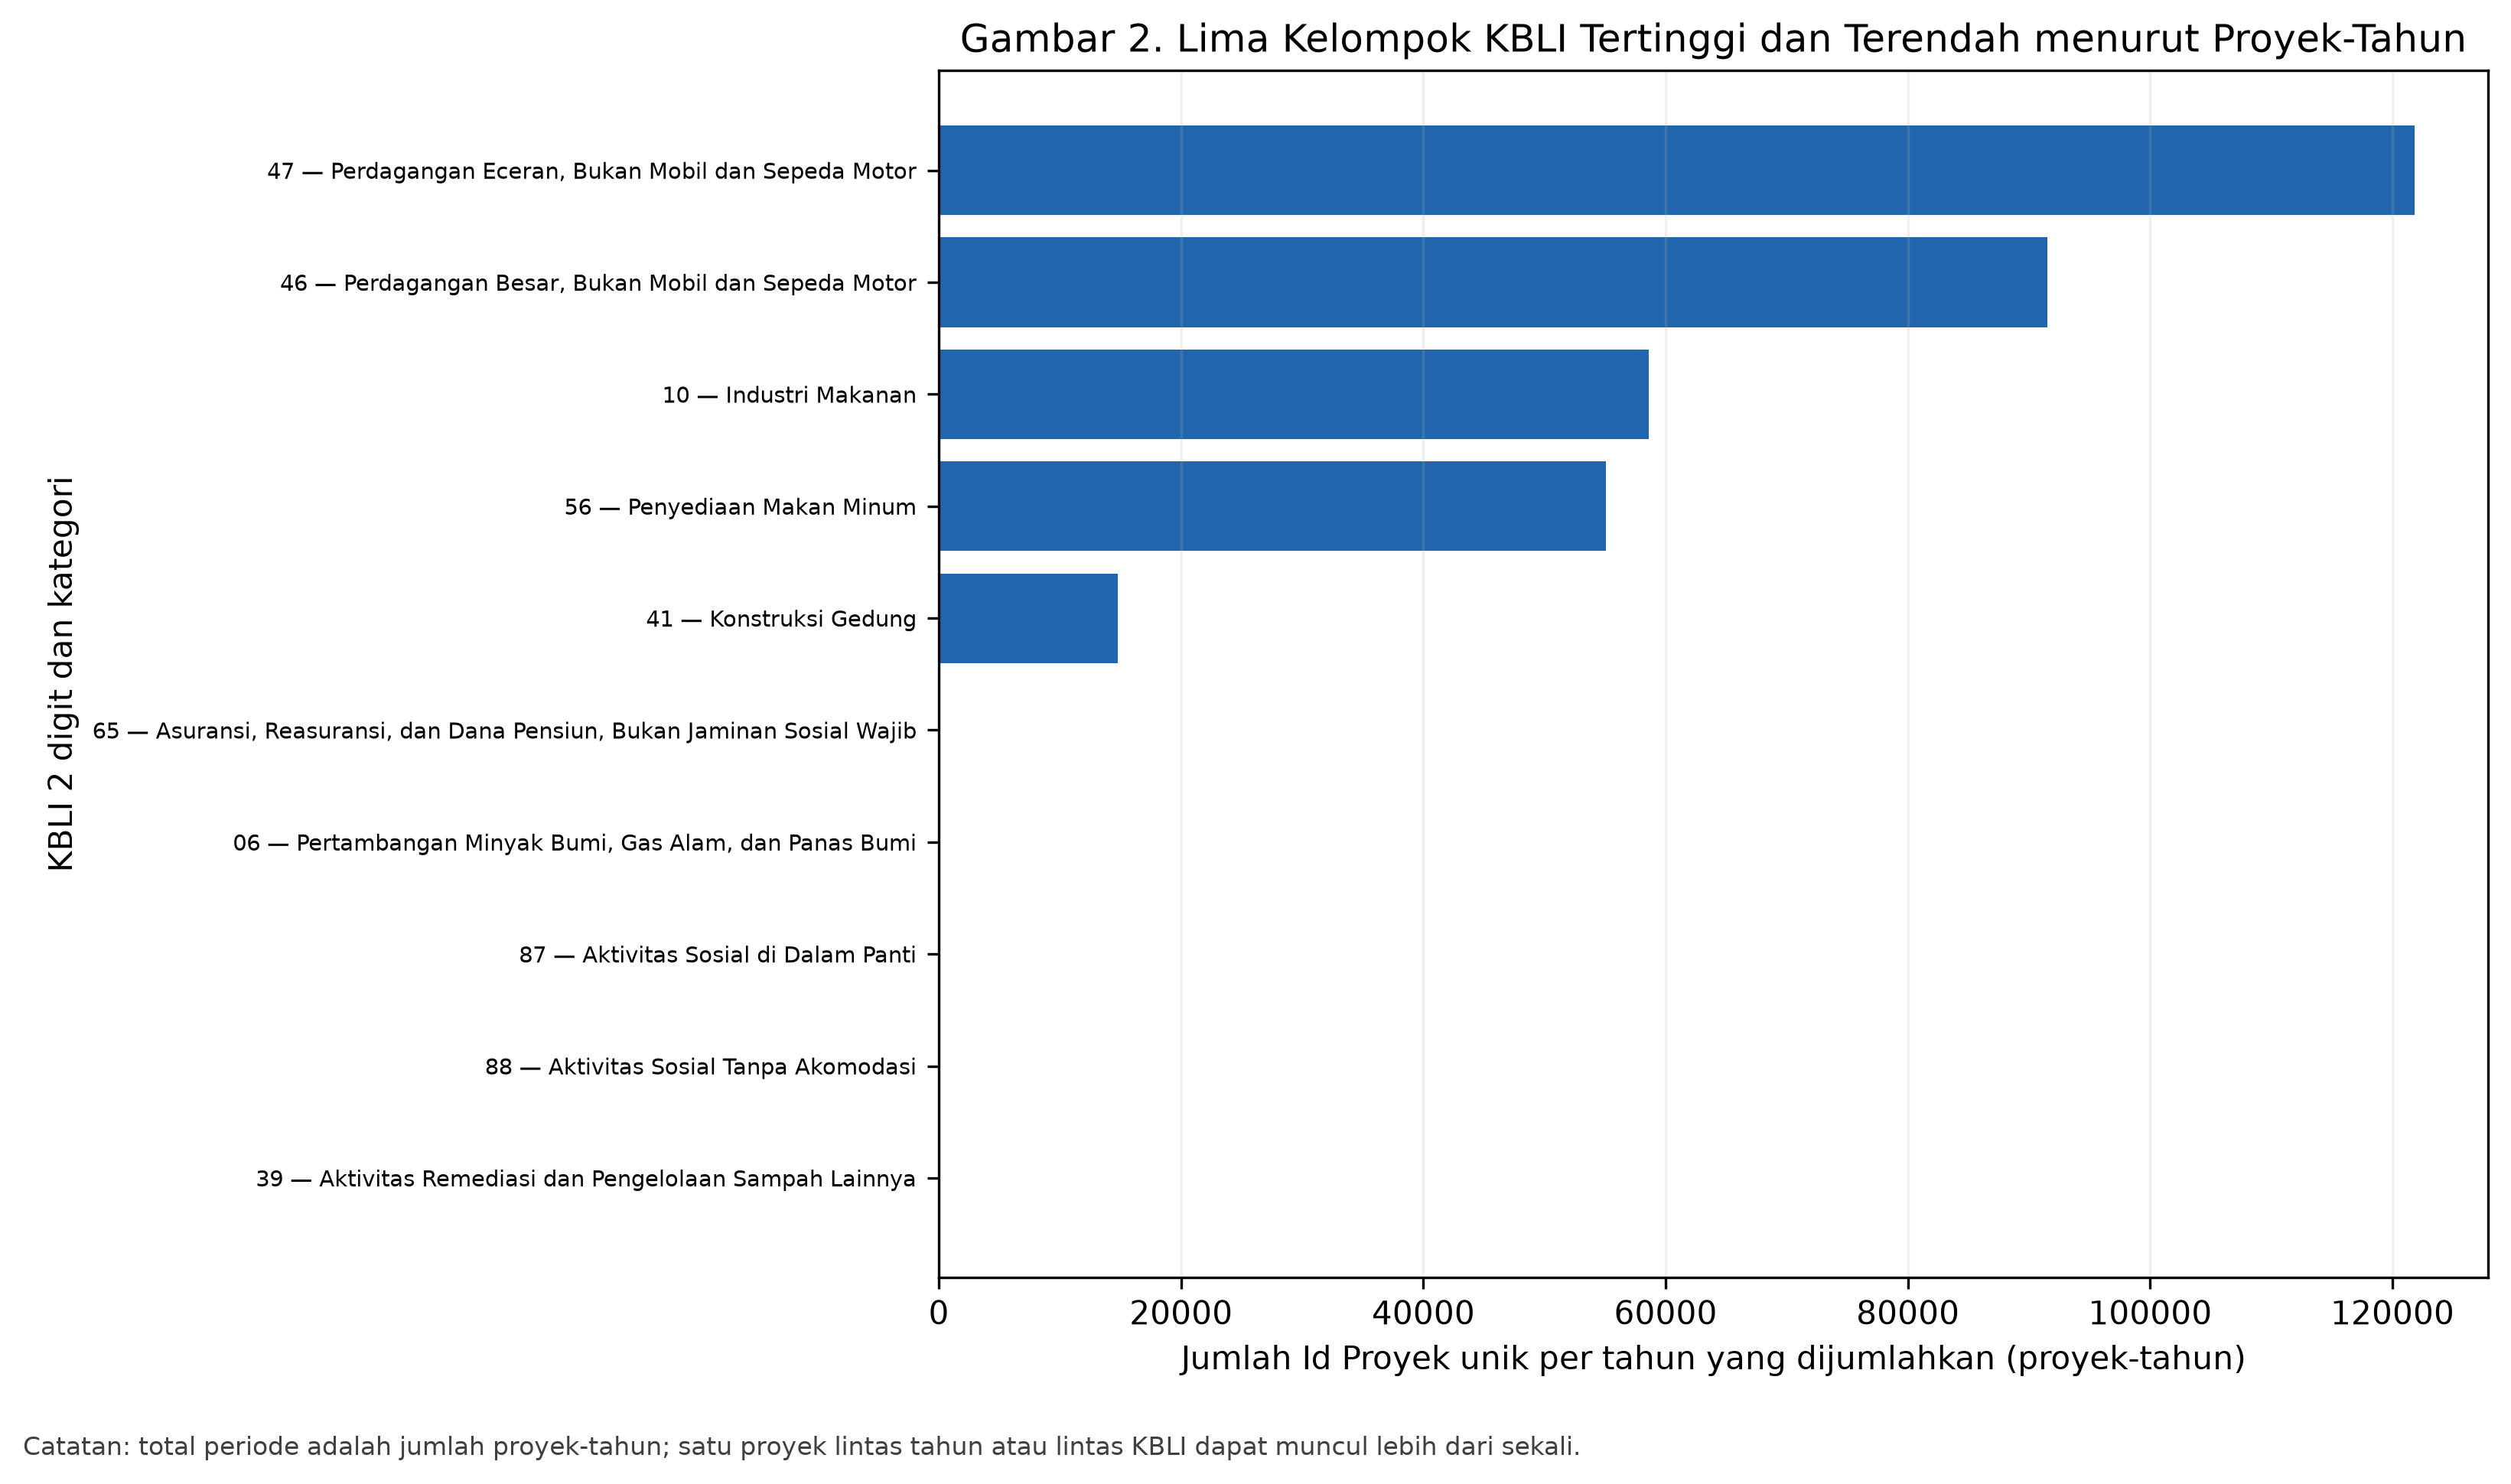

#### Gambar 3. Lima kecamatan tertinggi dan terendah menurut proyek-tahun

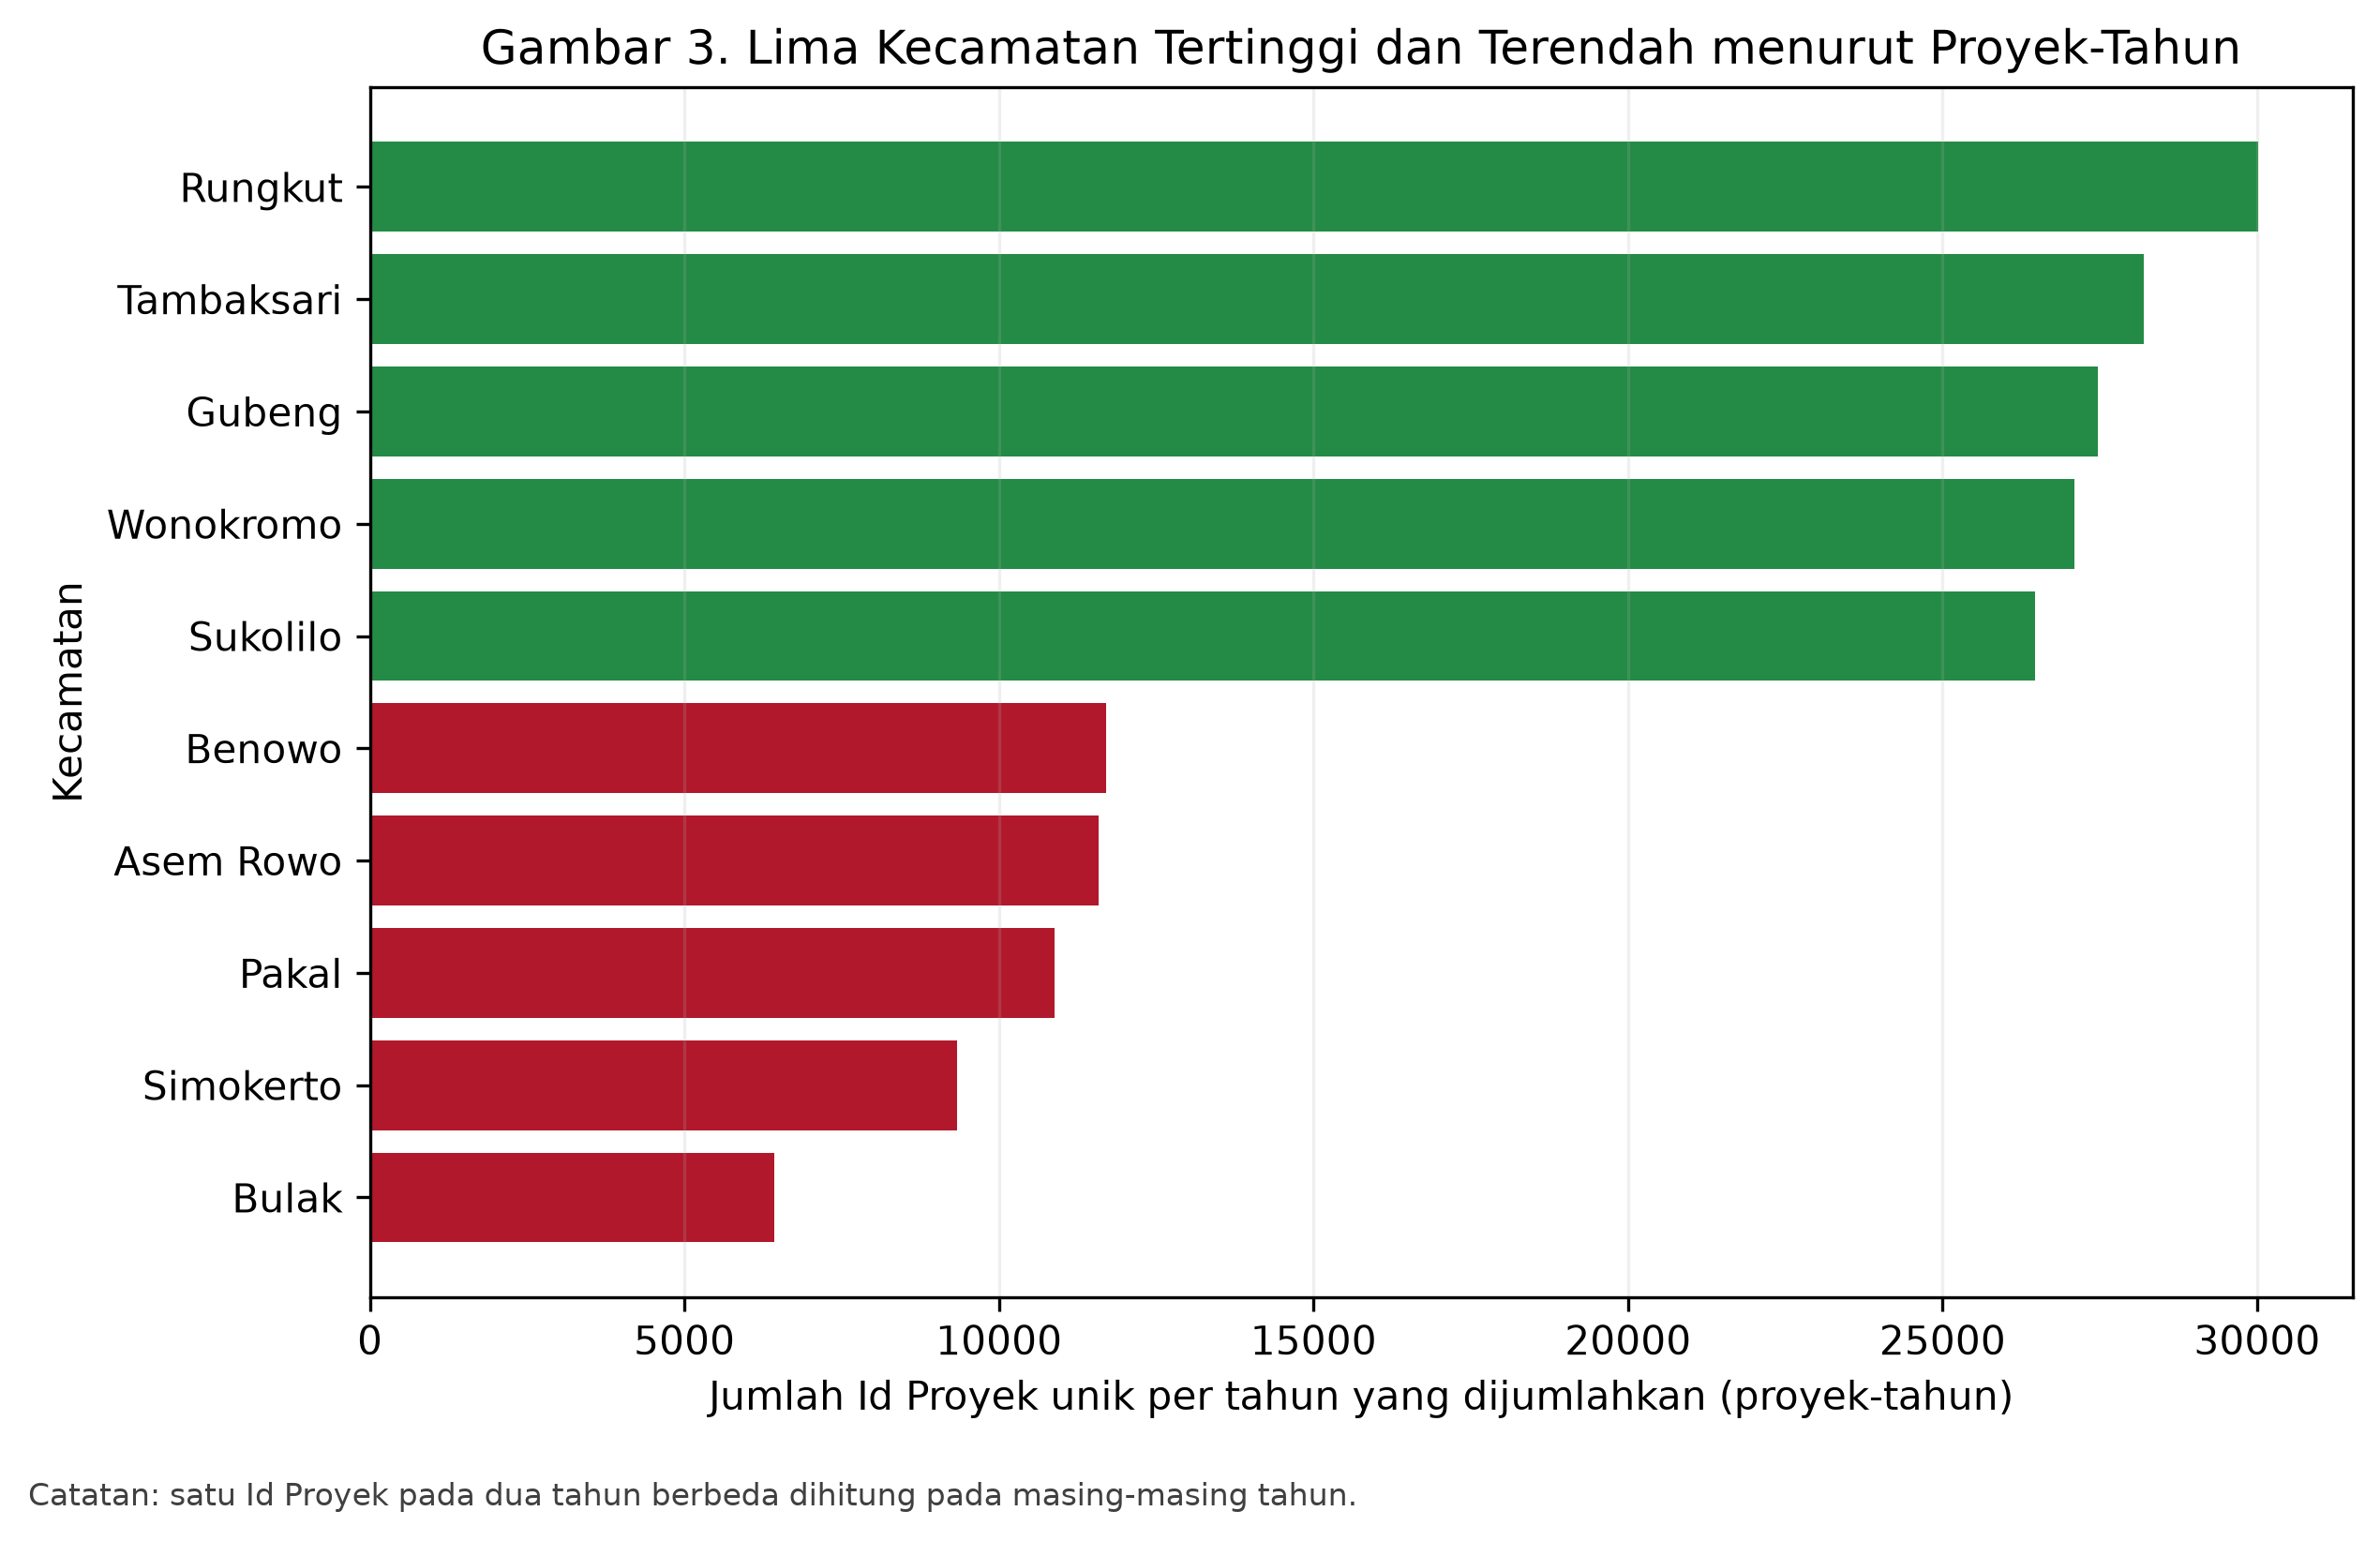

KBLI dengan jumlah proyek-tahun tertinggi adalah **47 - Perdagangan Eceran, Bukan Mobil dan Sepeda Motor** (121.802); terendah **39 - Aktivitas Remediasi dan Pengelolaan Sampah Lainnya** (8). Satu `Id Proyek` dapat muncul pada lebih dari satu KBLI.

Kecamatan dengan jumlah proyek-tahun tertinggi adalah **Rungkut** (30.012); terendah **Bulak** (6.426). Hitungan per kecamatan unik dalam pasangan kecamatan-tahun; agregat antarkecamatan tidak selalu sama dengan total unik kota.

In [3]:
sector_summary = TABLES['Tabel_02_ringkasan_lima_sektor_tertinggi_terendah']
sector_total = 'jumlah_kegiatan_2021_2025_proyek_tahun'
top_sectors = sector_summary.nlargest(5, sector_total).copy()
top_sectors.insert(0, 'Peringkat', range(1, len(top_sectors) + 1))
top_sectors.insert(1, 'Kelompok', 'Top 5')
bottom_sectors = sector_summary.nsmallest(5, sector_total).copy()
bottom_sectors.insert(0, 'Peringkat', range(1, len(bottom_sectors) + 1))
bottom_sectors.insert(1, 'Kelompok', 'Bottom 5')
kbli_rankings = pd.concat([top_sectors, bottom_sectors], ignore_index=True)
show_frame(
    'Tabel 2. Lima kelompok KBLI tertinggi dan terendah, 2021-2025',
    kbli_rankings[['Peringkat', 'Kelompok', 'KBLI_2digit', 'nama_kategori_kbli_2digit', sector_total]],
)

district_summary = TABLES['Tabel_03_ringkasan_lima_kecamatan_tertinggi_terendah']
district_total = 'jumlah_kegiatan_2021_2025_proyek_tahun'
top_districts = district_summary.nlargest(5, district_total).copy()
top_districts.insert(0, 'Peringkat', range(1, len(top_districts) + 1))
top_districts.insert(1, 'Kelompok', 'Top 5')
bottom_districts = district_summary.nsmallest(5, district_total).copy()
bottom_districts.insert(0, 'Peringkat', range(1, len(bottom_districts) + 1))
bottom_districts.insert(1, 'Kelompok', 'Bottom 5')
district_rankings = pd.concat([top_districts, bottom_districts], ignore_index=True)
show_frame(
    'Tabel 3. Lima kecamatan tertinggi dan terendah, 2021-2025',
    district_rankings[['Peringkat', 'Kelompok', 'kecamatan_usaha', district_total]],
)
show_figure('Gambar 1. Jumlah kegiatan usaha unik Kota Surabaya, 2021-2025', 'Gambar_01_jumlah_kegiatan_tahunan.png')
show_figure('Gambar 2. Lima kelompok KBLI tertinggi dan terendah menurut proyek-tahun', 'Gambar_02_top_bottom_kbli.png')
show_figure('Gambar 3. Lima kecamatan tertinggi dan terendah menurut proyek-tahun', 'Gambar_03_top_bottom_kecamatan.png')

top_sector = top_sectors.iloc[0]
bottom_sector = bottom_sectors.iloc[0]
top_district = top_districts.iloc[0]
bottom_district = bottom_districts.iloc[0]
display(Markdown(
    f"KBLI dengan jumlah proyek-tahun tertinggi adalah **{top_sector['KBLI_2digit']} - "
    f"{top_sector['nama_kategori_kbli_2digit']}** ({format_number(top_sector[sector_total])}); "
    f"terendah **{bottom_sector['KBLI_2digit']} - {bottom_sector['nama_kategori_kbli_2digit']}** "
    f"({format_number(bottom_sector[sector_total])}). Satu `Id Proyek` dapat muncul pada lebih dari satu KBLI."
))
display(Markdown(
    f"Kecamatan dengan jumlah proyek-tahun tertinggi adalah **{top_district['kecamatan_usaha']}** "
    f"({format_number(top_district[district_total])}); terendah **{bottom_district['kecamatan_usaha']}** "
    f"({format_number(bottom_district[district_total])}). Hitungan per kecamatan unik dalam pasangan "
    "kecamatan-tahun; agregat antarkecamatan tidak selalu sama dengan total unik kota."
))

## 4. Pertumbuhan kegiatan usaha berdasarkan KBLI

Tabel pertumbuhan memuat jumlah aktual per tahun, perubahan absolut dan persentase YoY, serta perubahan kumulatif 2021-2025. Tahun 2021 adalah baseline sehingga YoY-nya kosong. Persentase, terutama pada entitas dengan nilai awal kecil, perlu dibaca bersama jumlah kegiatan aktual. Grafik sektor menampilkan perubahan absolut dan tren KBLI terpilih agar tidak terlalu padat.

### Pertumbuhan menurut KBLI 2 digit

#### Tabel 4. Pertumbuhan kegiatan usaha menurut KBLI 2 digit

Kode KBLI 2 digit,Tahun,Jumlah kegiatan usaha,Perubahan absolut YoY,Pertumbuhan YoY (%),Perubahan kumulatif 2021-2025,Perubahan kumulatif (%),Nama KBLI 2 digit
01,2.021,529,,,246,"46,50","Pertanian Tanaman, Peternakan, Perburuan, dan Kegiatan YBDI"
01,2.022,946,417,"78,83",246,"46,50","Pertanian Tanaman, Peternakan, Perburuan, dan Kegiatan YBDI"
01,2.023,809,-137,"-14,48",246,"46,50","Pertanian Tanaman, Peternakan, Perburuan, dan Kegiatan YBDI"
01,2.024,730,-79,"-9,77",246,"46,50","Pertanian Tanaman, Peternakan, Perburuan, dan Kegiatan YBDI"
01,2.025,775,45,"6,16",246,"46,50","Pertanian Tanaman, Peternakan, Perburuan, dan Kegiatan YBDI"
02,2.021,26,,,27,"103,85",Kehutanan dan Penebangan Kayu
02,2.022,131,105,"403,85",27,"103,85",Kehutanan dan Penebangan Kayu
02,2.023,118,-13,"-9,92",27,"103,85",Kehutanan dan Penebangan Kayu
02,2.024,71,-47,"-39,83",27,"103,85",Kehutanan dan Penebangan Kayu
02,2.025,53,-18,"-25,35",27,"103,85",Kehutanan dan Penebangan Kayu


#### Gambar 4. Sepuluh kenaikan dan penurunan absolut terbesar menurut KBLI

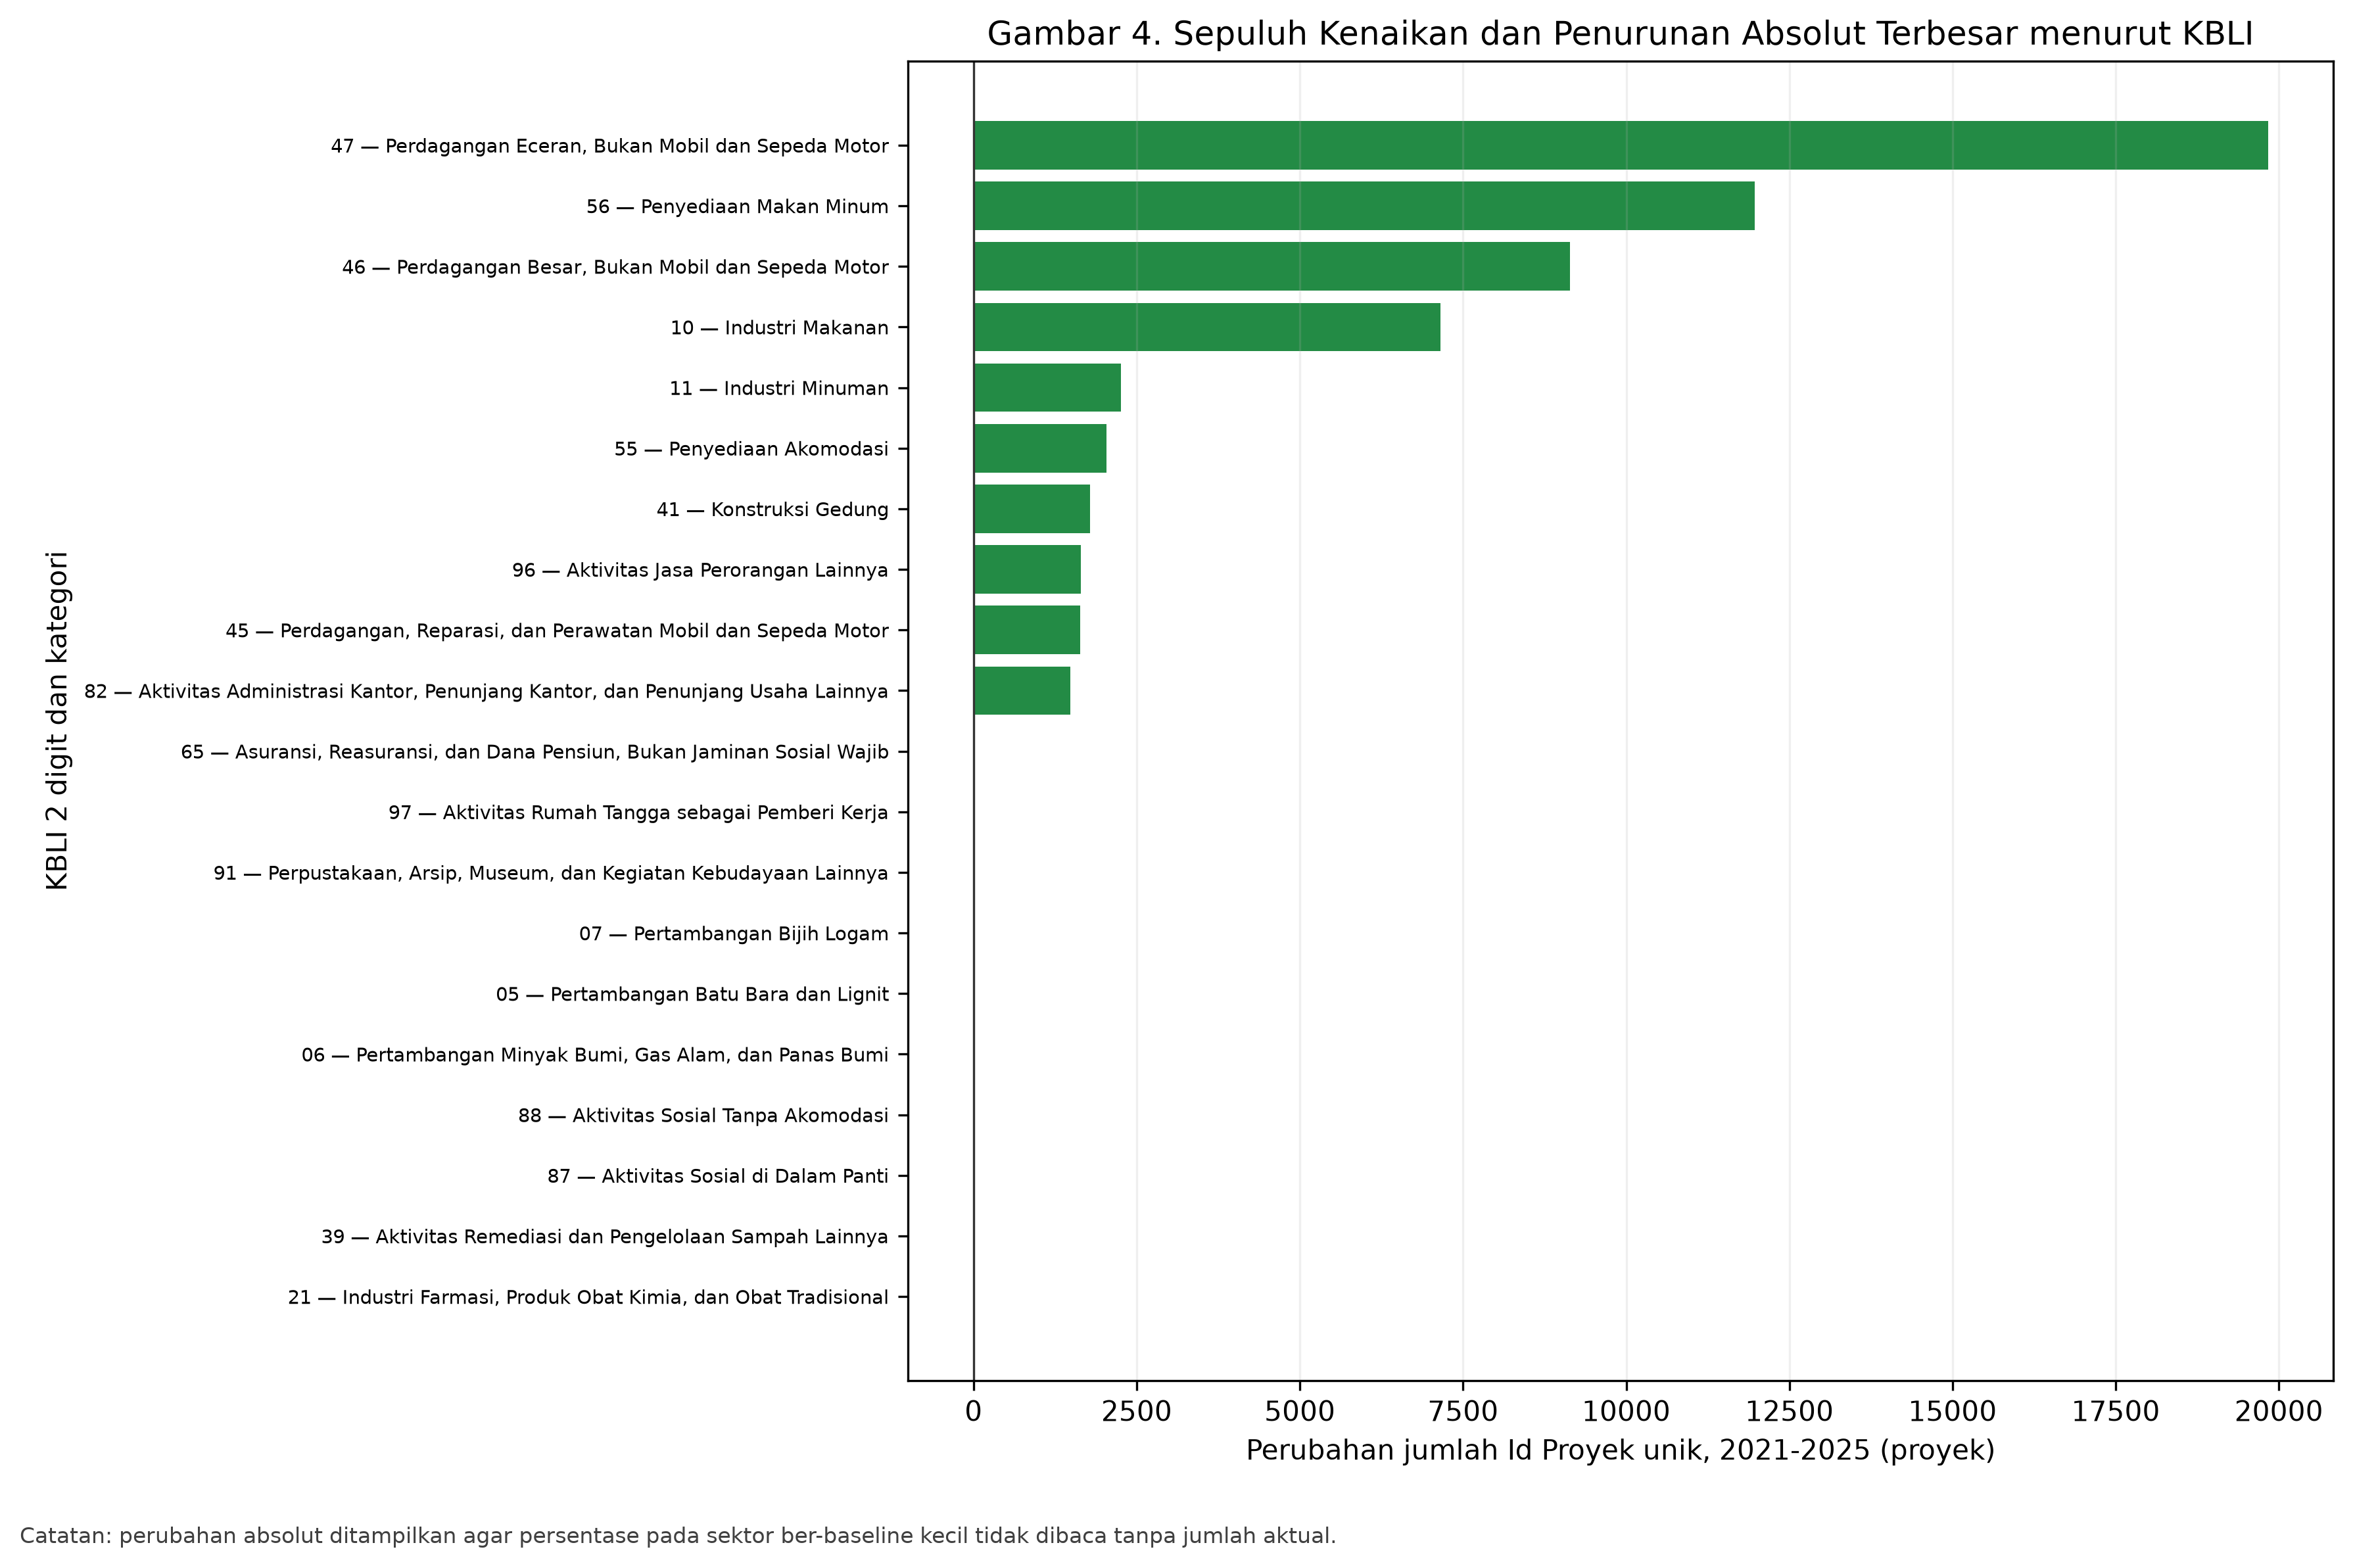

#### Gambar 6. Perkembangan tahunan kelompok KBLI yang menonjol

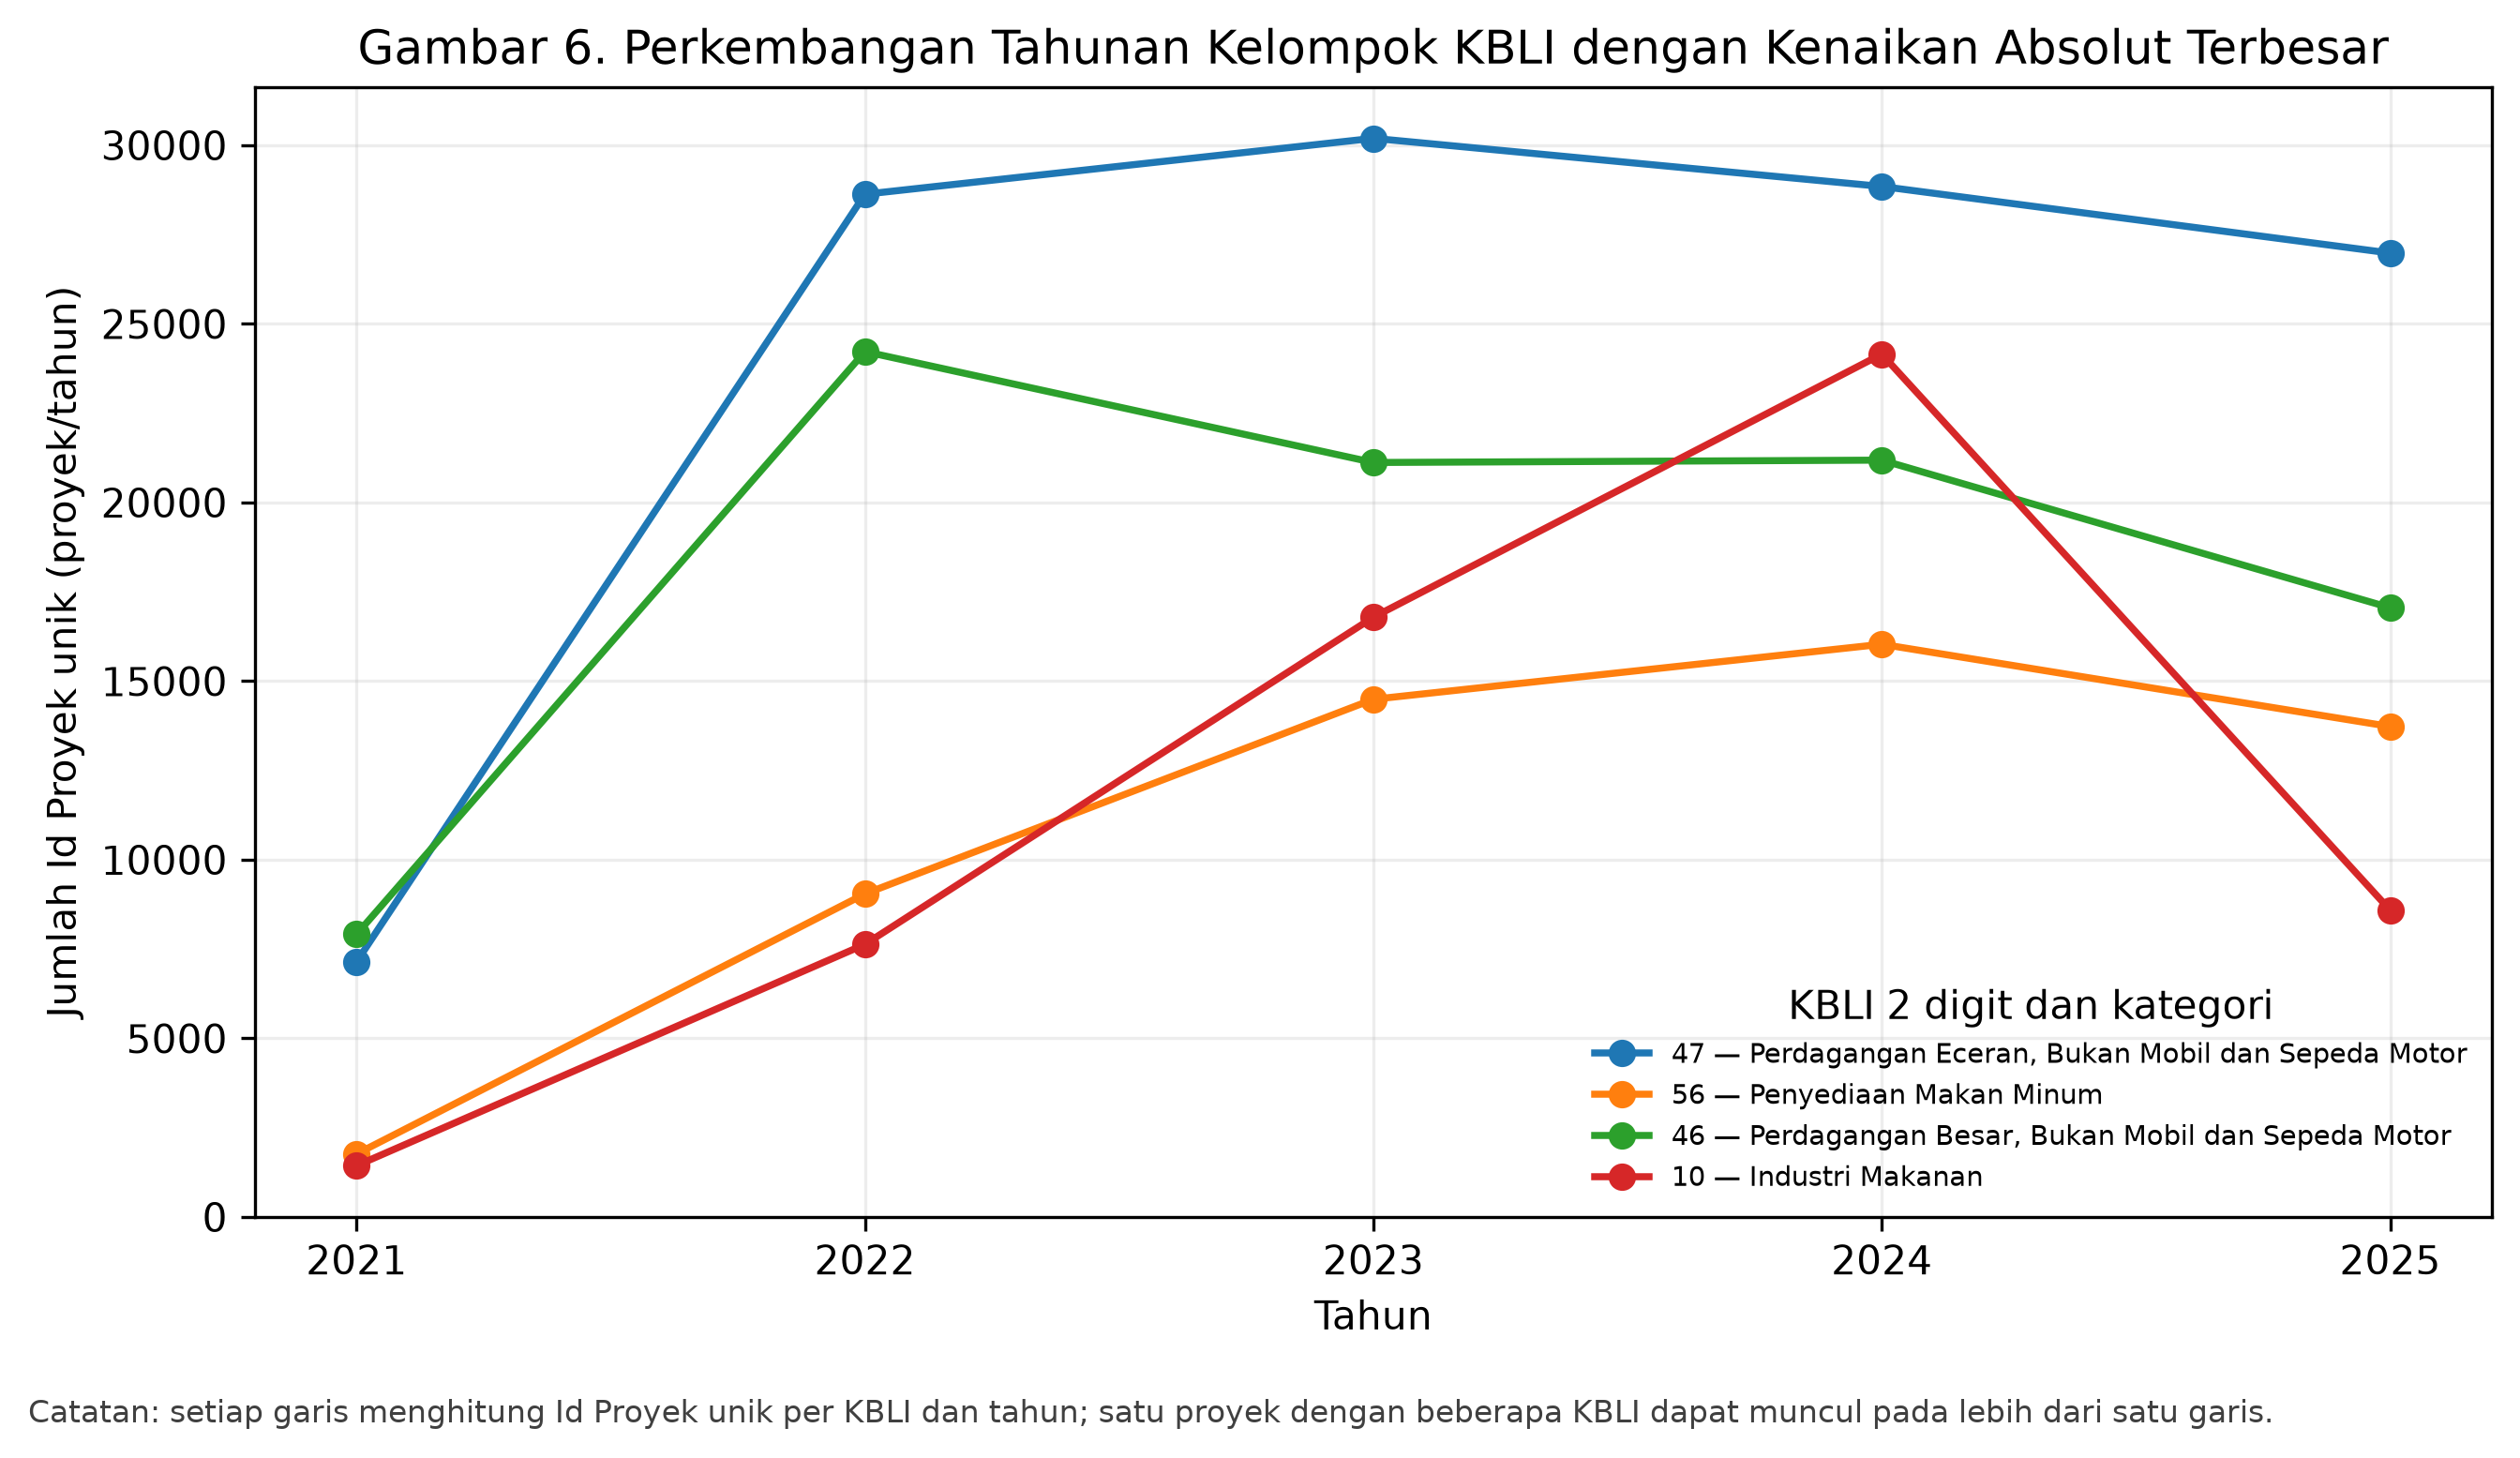

Perubahan kumulatif absolut terbesar terdapat pada **KBLI 47 - Perdagangan Eceran, Bukan Mobil dan Sepeda Motor** (+19.841 proyek-tahun dari baseline); penurunan terbesar terdapat pada **KBLI 21 - Industri Farmasi, Produk Obat Kimia, dan Obat Tradisional** (-10). Tren KBLI terpilih memperlihatkan skala aktual per tahun; persentase pertumbuhan tidak dibaca terpisah dari jumlahnya.

## 5. Pertumbuhan kegiatan usaha berdasarkan kecamatan

#### Tabel 5. Pertumbuhan kegiatan usaha menurut kecamatan

Kecamatan,Tahun,Jumlah kegiatan usaha,Perubahan absolut YoY,Pertumbuhan YoY (%),Perubahan kumulatif 2021-2025,Perubahan kumulatif (%)
Asem Rowo,2.021,663,,,1.796,"270,89"
Asem Rowo,2.022,3.101,2.438,"367,72",1.796,"270,89"
Asem Rowo,2.023,2.575,-526,"-16,96",1.796,"270,89"
Asem Rowo,2.024,2.783,208,"8,08",1.796,"270,89"
Asem Rowo,2.025,2.459,-324,"-11,64",1.796,"270,89"
Benowo,2.021,626,,,2.108,"336,74"
Benowo,2.022,2.604,1.978,"315,97",2.108,"336,74"
Benowo,2.023,2.594,-10,"-0,38",2.108,"336,74"
Benowo,2.024,3.139,545,"21,01",2.108,"336,74"
Benowo,2.025,2.734,-405,"-12,90",2.108,"336,74"


#### Gambar 5. Perubahan absolut kegiatan usaha per kecamatan

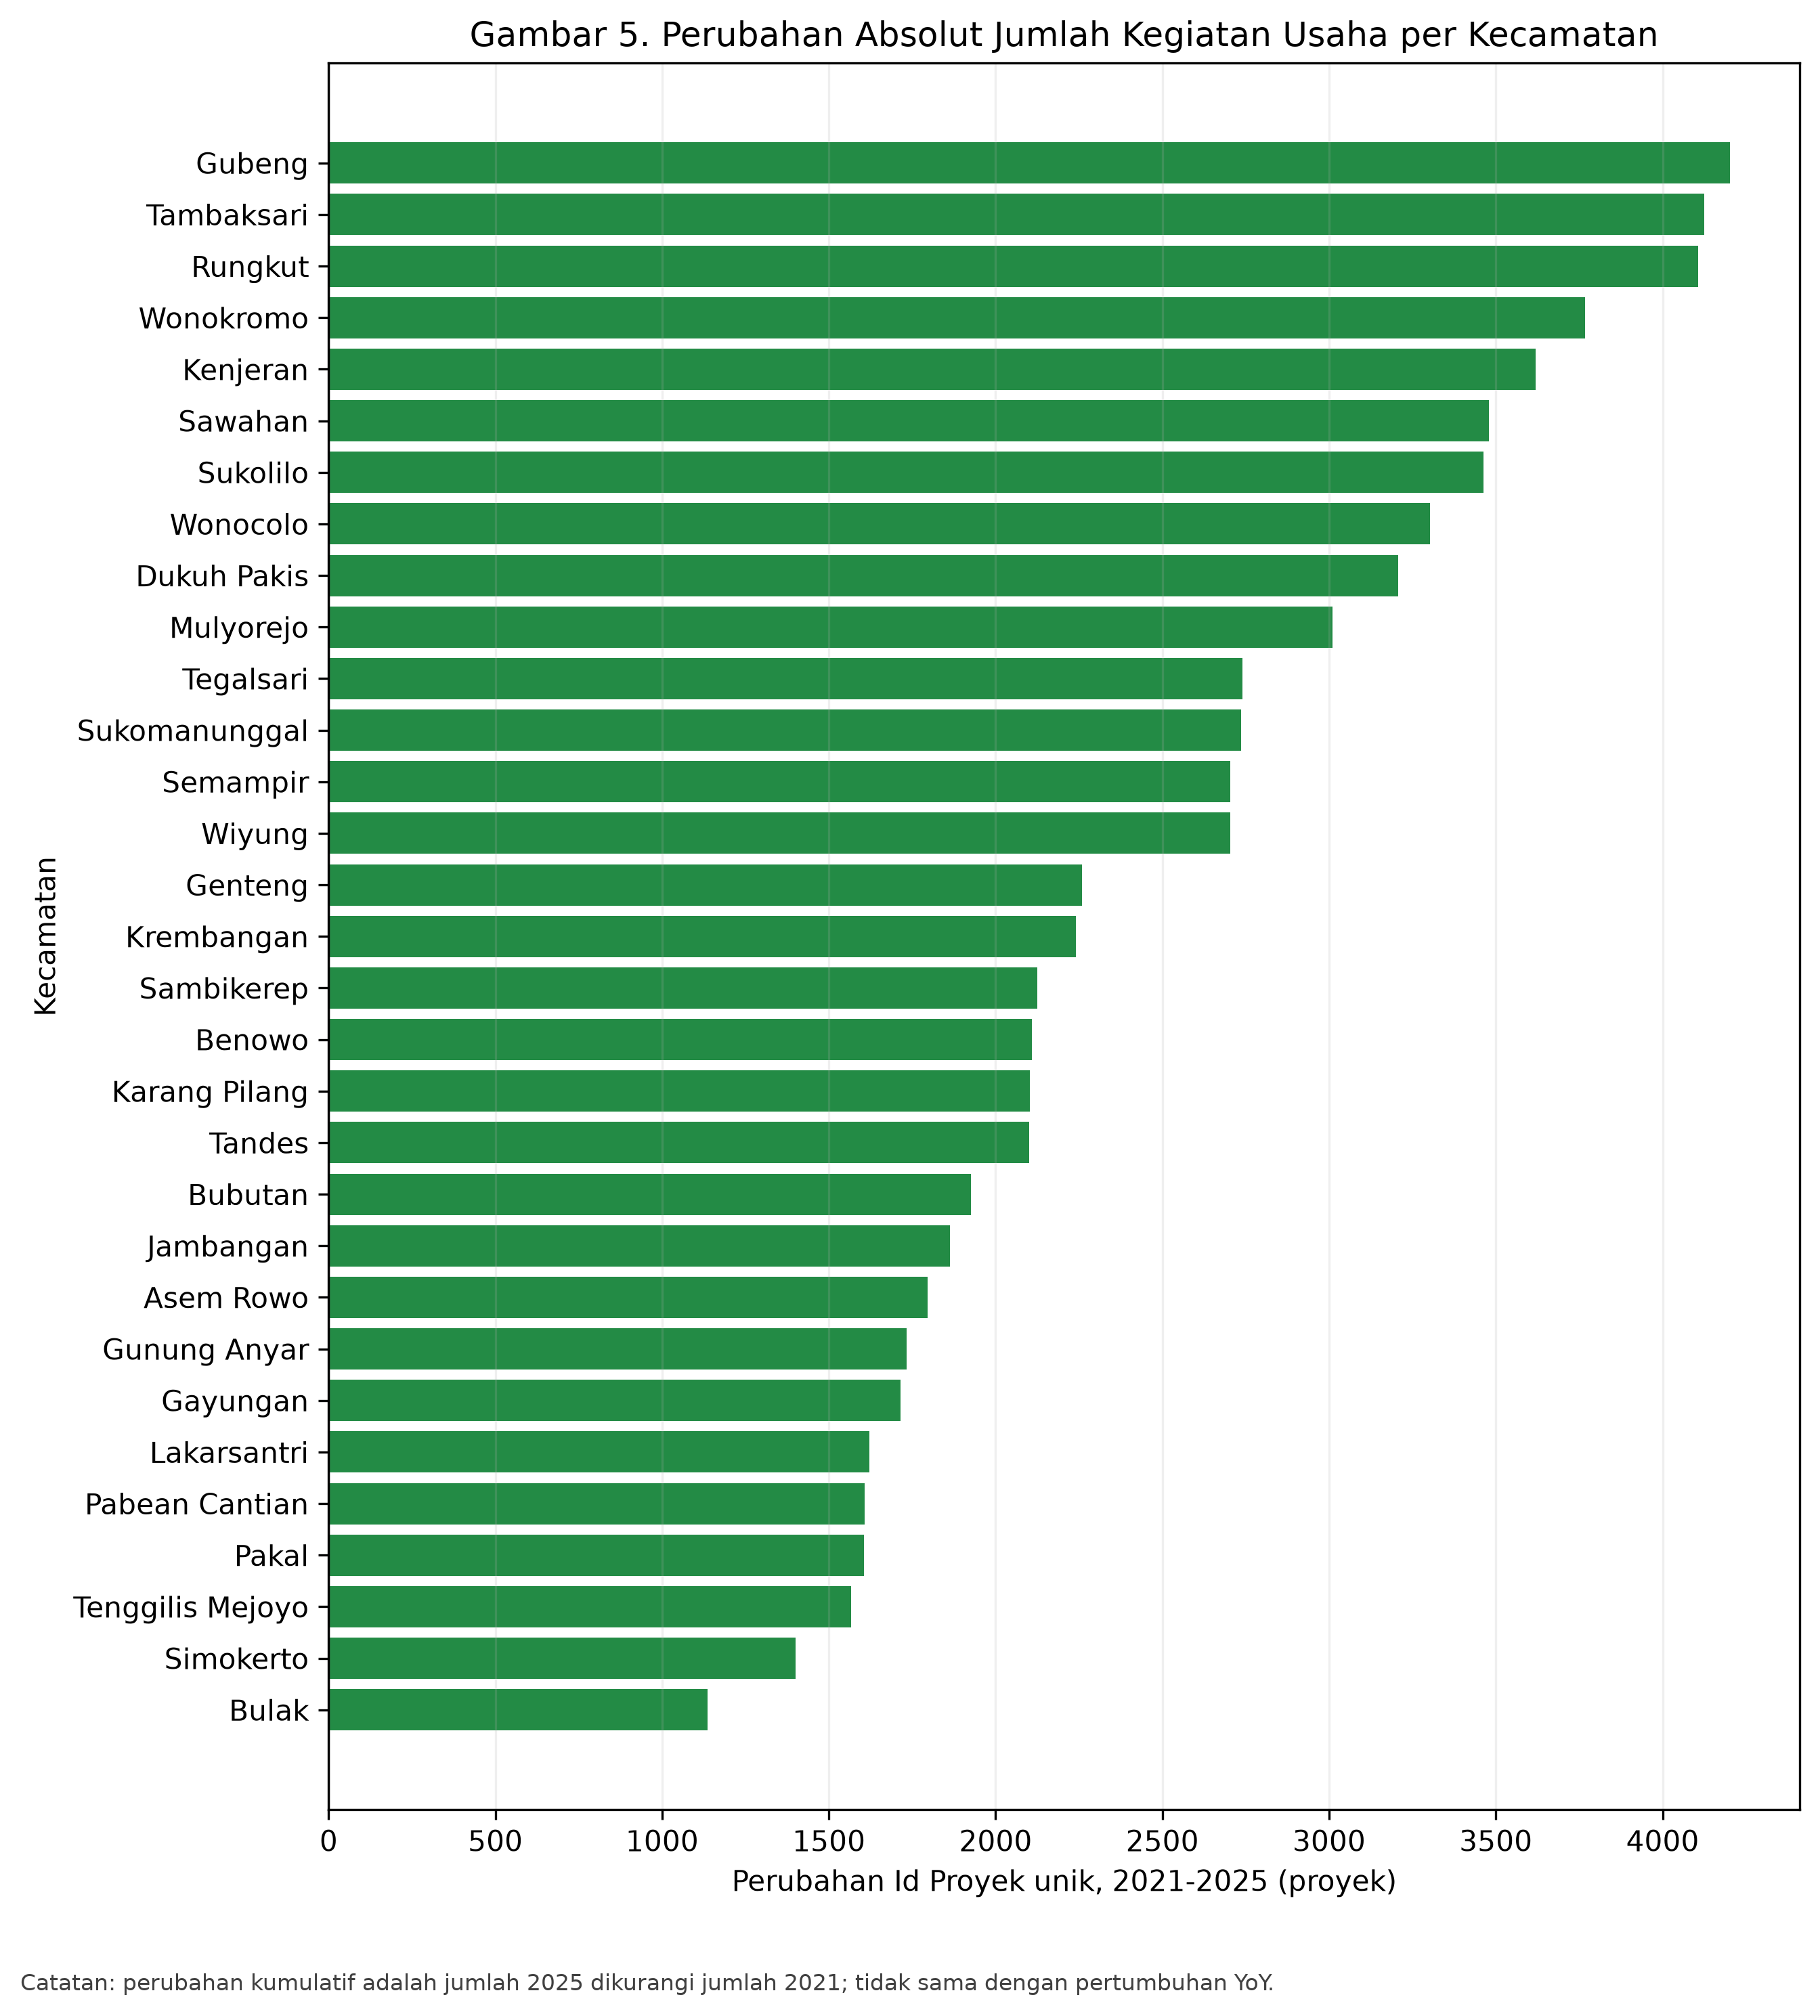

Perubahan kumulatif absolut tertinggi terdapat di **Gubeng** (+4.201 kegiatan), sedangkan terendah di **Bulak** (1.137). Perbandingan ini menunjukkan perubahan absolut; persentase kecamatan dengan baseline kecil perlu dibaca hati-hati.

In [4]:
display(Markdown('### Pertumbuhan menurut KBLI 2 digit'))
show_table('Tabel 4. Pertumbuhan kegiatan usaha menurut KBLI 2 digit', 'Tabel_04_pertumbuhan_kegiatan_sektor')
show_figure('Gambar 4. Sepuluh kenaikan dan penurunan absolut terbesar menurut KBLI', 'Gambar_04_pertumbuhan_absolut_sektor.png')
show_figure('Gambar 6. Perkembangan tahunan kelompok KBLI yang menonjol', 'Gambar_06_tren_sektor_menonjol.png')
sector_2025 = TABLES['Tabel_04_pertumbuhan_kegiatan_sektor'].loc[
    TABLES['Tabel_04_pertumbuhan_kegiatan_sektor']['Tahun'].eq(2025)
]
sector_top_change = sector_2025.sort_values(
    'perubahan_kumulatif_2021_2025_jumlah', ascending=False
).iloc[0]
sector_bottom_change = sector_2025.sort_values(
    'perubahan_kumulatif_2021_2025_jumlah', ascending=True
).iloc[0]
display(Markdown(
    f"Perubahan kumulatif absolut terbesar terdapat pada **KBLI {sector_top_change['KBLI_2digit']} - "
    f"{sector_top_change['nama_kategori_kbli_2digit']}** (+{format_number(sector_top_change['perubahan_kumulatif_2021_2025_jumlah'])} "
    f"proyek-tahun dari baseline); penurunan terbesar terdapat pada **KBLI {sector_bottom_change['KBLI_2digit']} - "
    f"{sector_bottom_change['nama_kategori_kbli_2digit']}** ({format_number(sector_bottom_change['perubahan_kumulatif_2021_2025_jumlah'])}). "
    "Tren KBLI terpilih memperlihatkan skala aktual per tahun; persentase pertumbuhan tidak dibaca terpisah dari jumlahnya."
))

display(Markdown('## 5. Pertumbuhan kegiatan usaha berdasarkan kecamatan'))
show_table('Tabel 5. Pertumbuhan kegiatan usaha menurut kecamatan', 'Tabel_05_pertumbuhan_kegiatan_kecamatan')
show_figure('Gambar 5. Perubahan absolut kegiatan usaha per kecamatan', 'Gambar_05_pertumbuhan_absolut_kecamatan.png')
district_2025 = TABLES['Tabel_05_pertumbuhan_kegiatan_kecamatan'].loc[
    TABLES['Tabel_05_pertumbuhan_kegiatan_kecamatan']['Tahun'].eq(2025)
]
district_top_change = district_2025.sort_values(
    'perubahan_kumulatif_2021_2025_jumlah', ascending=False
).iloc[0]
district_bottom_change = district_2025.sort_values(
    'perubahan_kumulatif_2021_2025_jumlah', ascending=True
).iloc[0]
display(Markdown(
    f"Perubahan kumulatif absolut tertinggi terdapat di **{district_top_change['kecamatan_usaha']}** "
    f"(+{format_number(district_top_change['perubahan_kumulatif_2021_2025_jumlah'])} kegiatan), sedangkan "
    f"terendah di **{district_bottom_change['kecamatan_usaha']}** "
    f"({format_number(district_bottom_change['perubahan_kumulatif_2021_2025_jumlah'])}). "
    "Perbandingan ini menunjukkan perubahan absolut; persentase kecamatan dengan baseline kecil perlu dibaca hati-hati."
))

## 6. Analisis Location Quotient (LQ)

Klasifikasi menggunakan LQ > 1 sebagai basis, LQ < 1 sebagai non-basis, dan LQ = 1 sebagai setara dengan struktur kota. Panel final mencakup 31 kecamatan x 83 KBLI x 5 tahun; kombinasi tanpa aktivitas bernilai LQ 0 bila sektor aktif di kota. LQ tinggi menunjukkan konsentrasi relatif, bukan jumlah absolut yang besar, sehingga harus dibaca bersama jumlah kegiatan aktual.

### Klasifikasi jumlah kombinasi kecamatan-KBLI

#### Tabel 6. Jumlah kombinasi kecamatan-KBLI menurut kategori LQ

Tahun,jumlah_kombinasi_kecamatan_kbli_dianalisis,kombinasi_lq_nol_sektor_aktif,kombinasi_dengan_kegiatan,Basis (LQ > 1),Non-basis (LQ < 1),Setara dengan struktur kota (LQ = 1),LQ tidak tersedia
2.021,2.573,835,1.738,916,1.657,0,0
2.022,2.573,406,2.167,1.007,1.566,0,0
2.023,2.573,354,2.126,962,1.518,0,93
2.024,2.573,380,2.131,1.031,1.480,0,62
2.025,2.573,362,2.118,969,1.511,0,93


#### Tabel 7. Lima kelompok KBLI dengan rerata LQ tertinggi per tahun

Kode KBLI 2 digit,Tahun,Rerata LQ 31 kecamatan,Nama KBLI 2 digit,Jumlah kegiatan sektor kota,Id Proyek unik sektor kota,Kecamatan dengan kegiatan,peringkat_lq_tahunan
06,2.021,"1,179","Pertambangan Minyak Bumi, Gas Alam, dan Panas Bumi",5,5,3,3
17,2.021,"1,190",Industri Kertas dan Barang dari Kertas,44,44,19,2
24,2.021,"1,246",Industri Logam Dasar,27,27,14,1
51,2.021,"1,162",Angkutan Udara,2,2,2,5
65,2.021,"1,166","Asuransi, Reasuransi, dan Dana Pensiun, Bukan Jaminan Sosial Wajib",2,2,2,4
19,2.022,"1,161",Industri Produk dari Batu Bara dan Pengilangan Minyak Bumi,32,32,22,5
24,2.022,"1,166",Industri Logam Dasar,105,105,25,4
39,2.022,"1,175",Aktivitas Remediasi dan Pengelolaan Sampah Lainnya,1,1,1,3
87,2.022,"1,175",Aktivitas Sosial di Dalam Panti,10,10,2,2
91,2.022,"1,224","Perpustakaan, Arsip, Museum, dan Kegiatan Kebudayaan Lainnya",12,12,9,1


#### Tabel 8. Lima kecamatan dengan LQ tertinggi untuk sektor terpilih

... (2 outputs left out)

Kode KBLI 2 digit,2021,2022,2023,2024,2025,Nama KBLI 2 digit,Tahun LQ tersedia,Rerata LQ 2021-2025,Perubahan rerata LQ,status_lq
01,"0,835","0,960","0,998","0,979","1,035","Pertanian Tanaman, Peternakan, Perburuan, dan Kegiatan YBDI",5,"0,962","0,200",Lengkap
02,"1,024","0,996","1,029","1,048","0,989",Kehutanan dan Penebangan Kayu,5,"1,017","-0,035",Lengkap
03,"0,857","1,103","1,164","1,008","1,031",Perikanan,5,"1,033","0,173",Lengkap
05,"0,935","0,895","1,088","1,294","0,915",Pertambangan Batu Bara dan Lignit,5,"1,025","-0,020",Lengkap
06,"1,179","0,973","0,955","1,005","0,816","Pertambangan Minyak Bumi, Gas Alam, dan Panas Bumi",5,"0,986","-0,363",Lengkap
07,"1,113","0,813","1,014","1,098","0,827",Pertambangan Bijih Logam,5,"0,973","-0,285",Lengkap
08,"0,903","1,049","1,128","1,195","0,831",Pertambangan dan Penggalian Lainnya,5,"1,021","-0,072",Lengkap
09,"0,880","0,979","1,025","1,082","1,040",Aktivitas Jasa Penunjang Pertambangan,5,"1,001","0,160",Lengkap
10,"1,053","1,050","0,989","0,984","0,996",Industri Makanan,5,"1,014","-0,057",Lengkap
11,"1,079","1,049","0,940","0,986","1,008",Industri Minuman,5,"1,012","-0,071",Lengkap


#### Tabel 13. Nilai LQ tertinggi beserta jumlah kegiatan aktual

peringkat_lq,Kode KBLI 2 digit,Nama KBLI 2 digit,Kecamatan,Jumlah kegiatan usaha,jumlah_kegiatan_sektor_kota_proyek_wilayah,Id Proyek unik sektor kota,Nilai LQ,Klasifikasi LQ
1,06,"Pertambangan Minyak Bumi, Gas Alam, dan Panas Bumi",Wonocolo,1,1,1,"25,292",Basis (LQ > 1)
2,65,"Asuransi, Reasuransi, dan Dana Pensiun, Bukan Jaminan Sosial Wajib",Benowo,2,6,6,"13,207",Basis (LQ > 1)
3,51,Angkutan Udara,Benowo,4,13,13,"12,191",Basis (LQ > 1)
4,91,"Perpustakaan, Arsip, Museum, dan Kegiatan Kebudayaan Lainnya",Tandes,3,12,12,"8,592",Basis (LQ > 1)
5,50,Angkutan Perairan,Pabean Cantian,47,252,252,"8,387",Basis (LQ > 1)
6,07,Pertambangan Bijih Logam,Wonocolo,4,13,13,"7,782",Basis (LQ > 1)
7,52,Pergudangan dan Aktivitas Penunjang Angkutan,Asem Rowo,269,1.569,1.569,"7,553",Basis (LQ > 1)
8,07,Pertambangan Bijih Logam,Sawahan,4,13,13,"7,395",Basis (LQ > 1)
9,05,Pertambangan Batu Bara dan Lignit,Genteng,2,9,9,"7,344",Basis (LQ > 1)
10,53,Pos dan Kurir,Krembangan,73,366,366,"7,319",Basis (LQ > 1)


#### Gambar 7. Jumlah kombinasi kecamatan-KBLI menurut kategori LQ

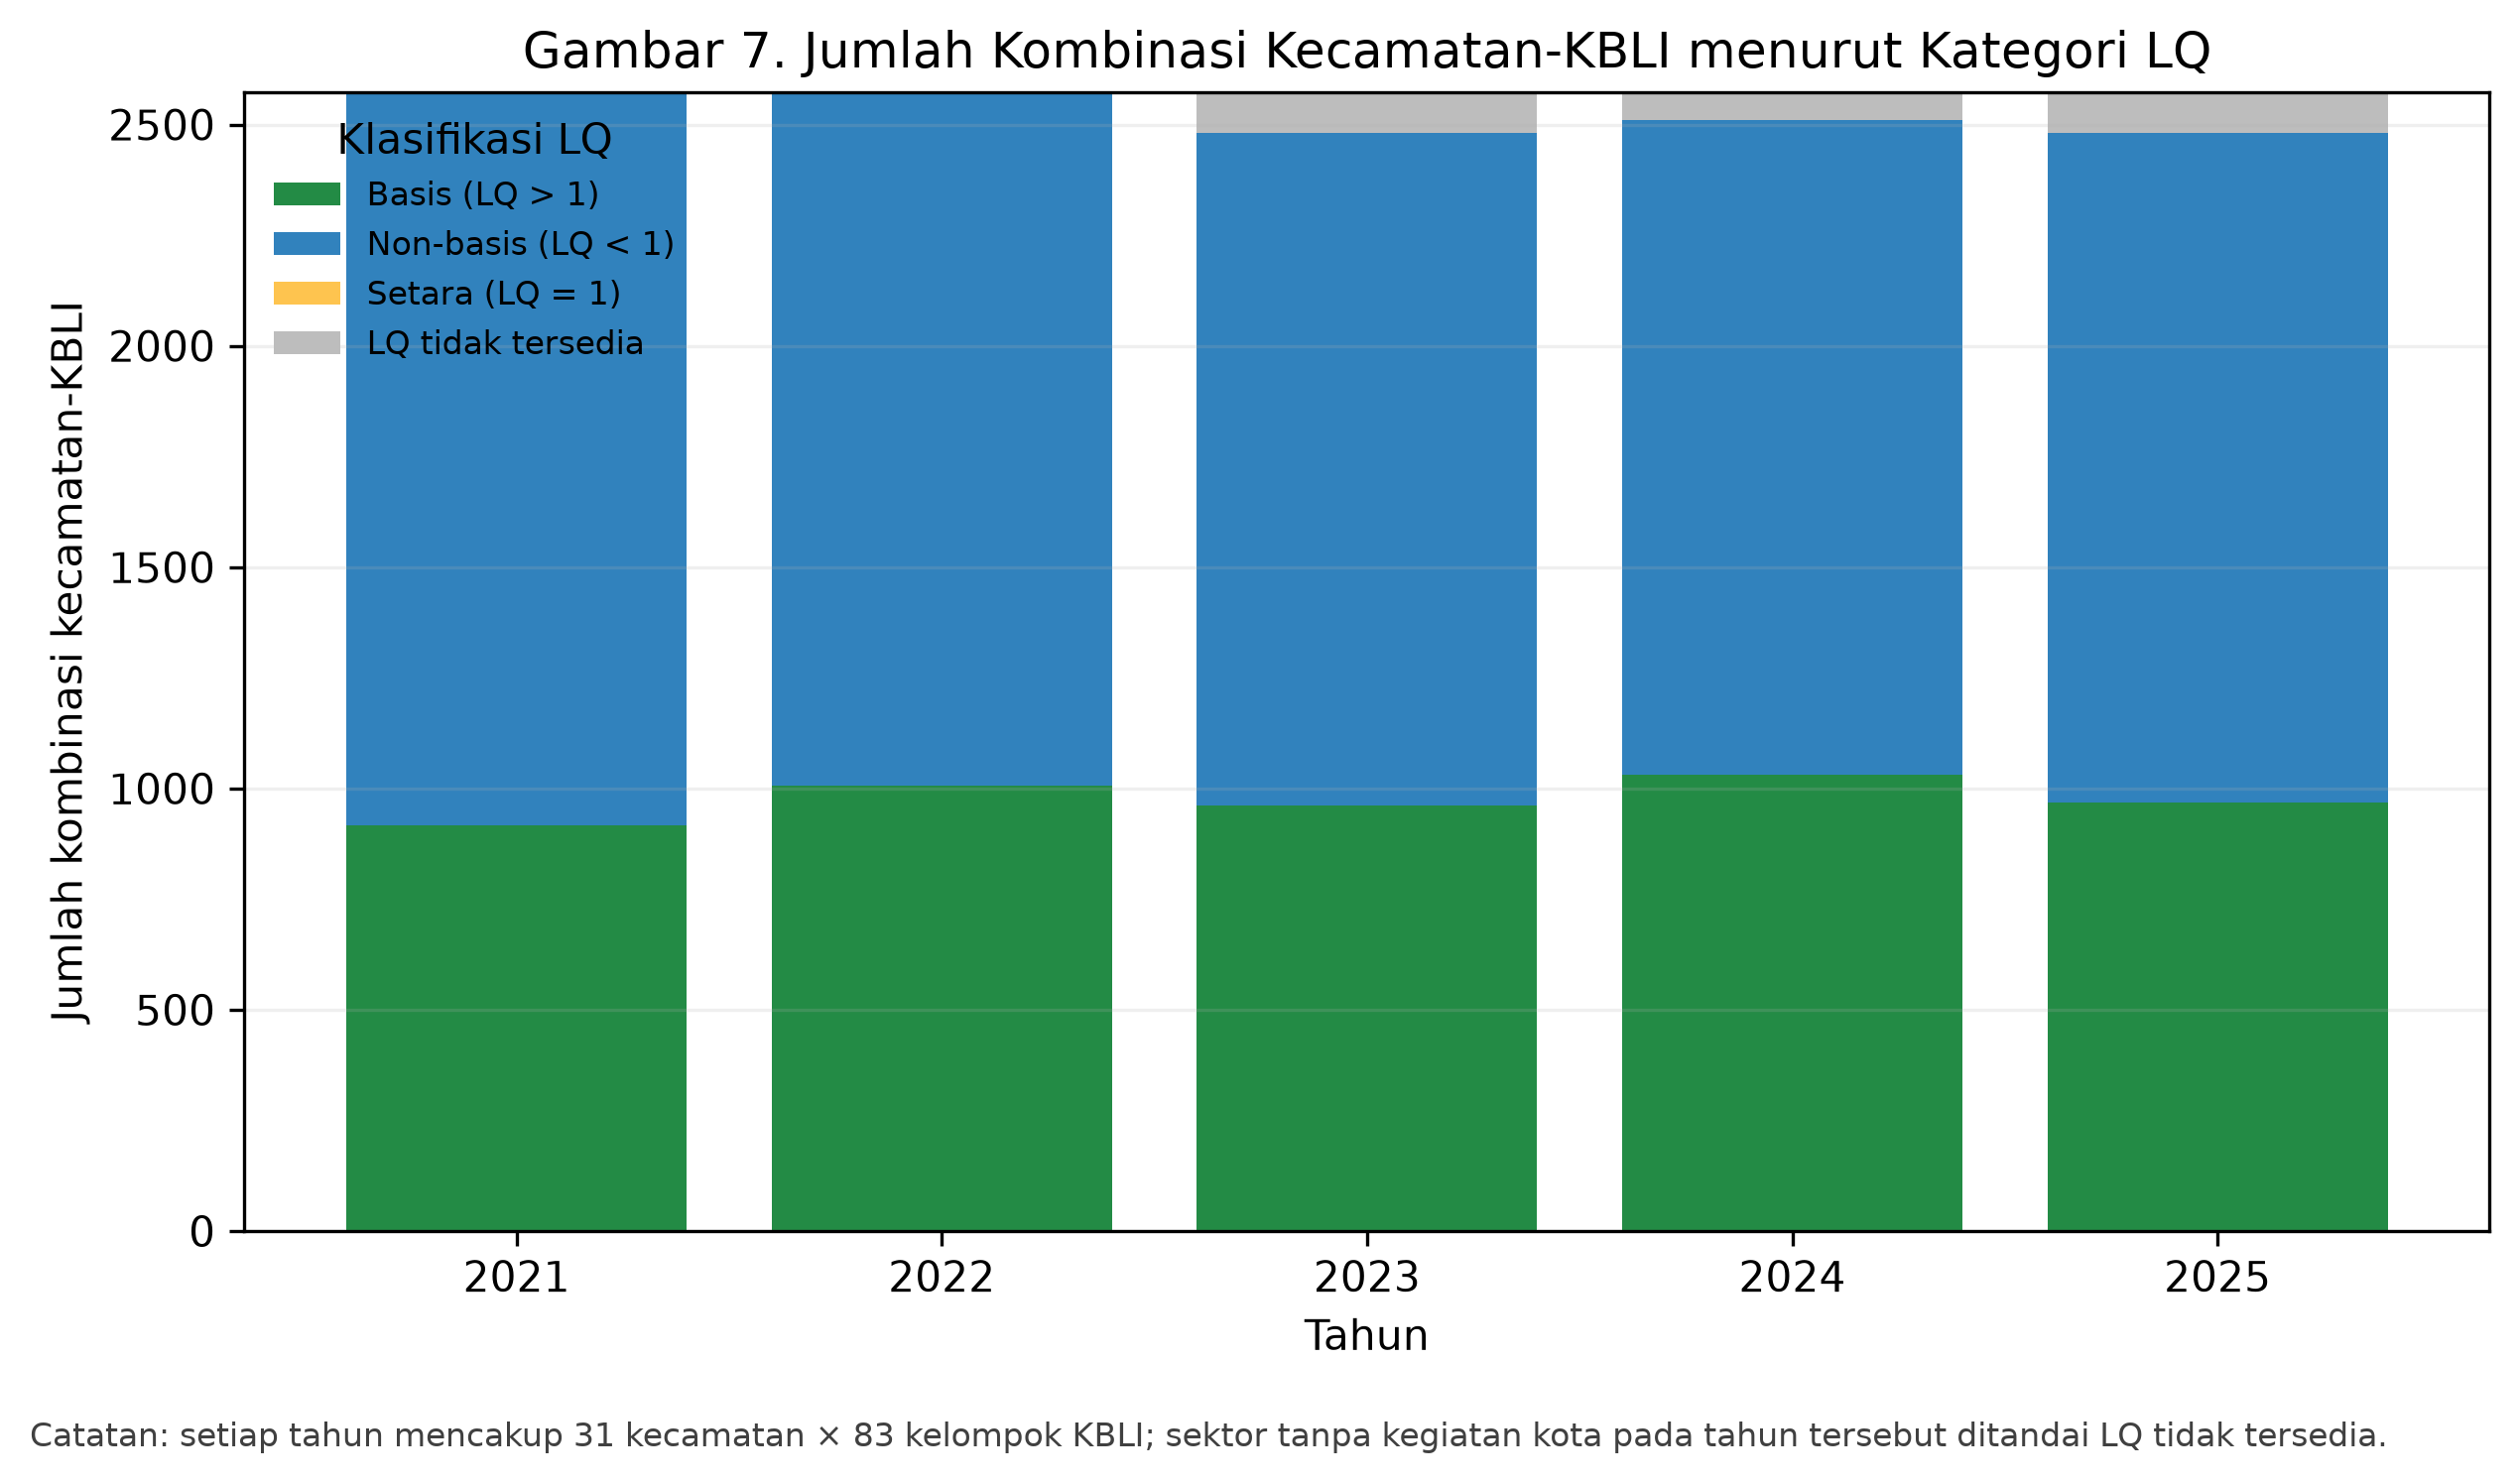

#### Gambar 8. Perbandingan rerata LQ sektor terpilih

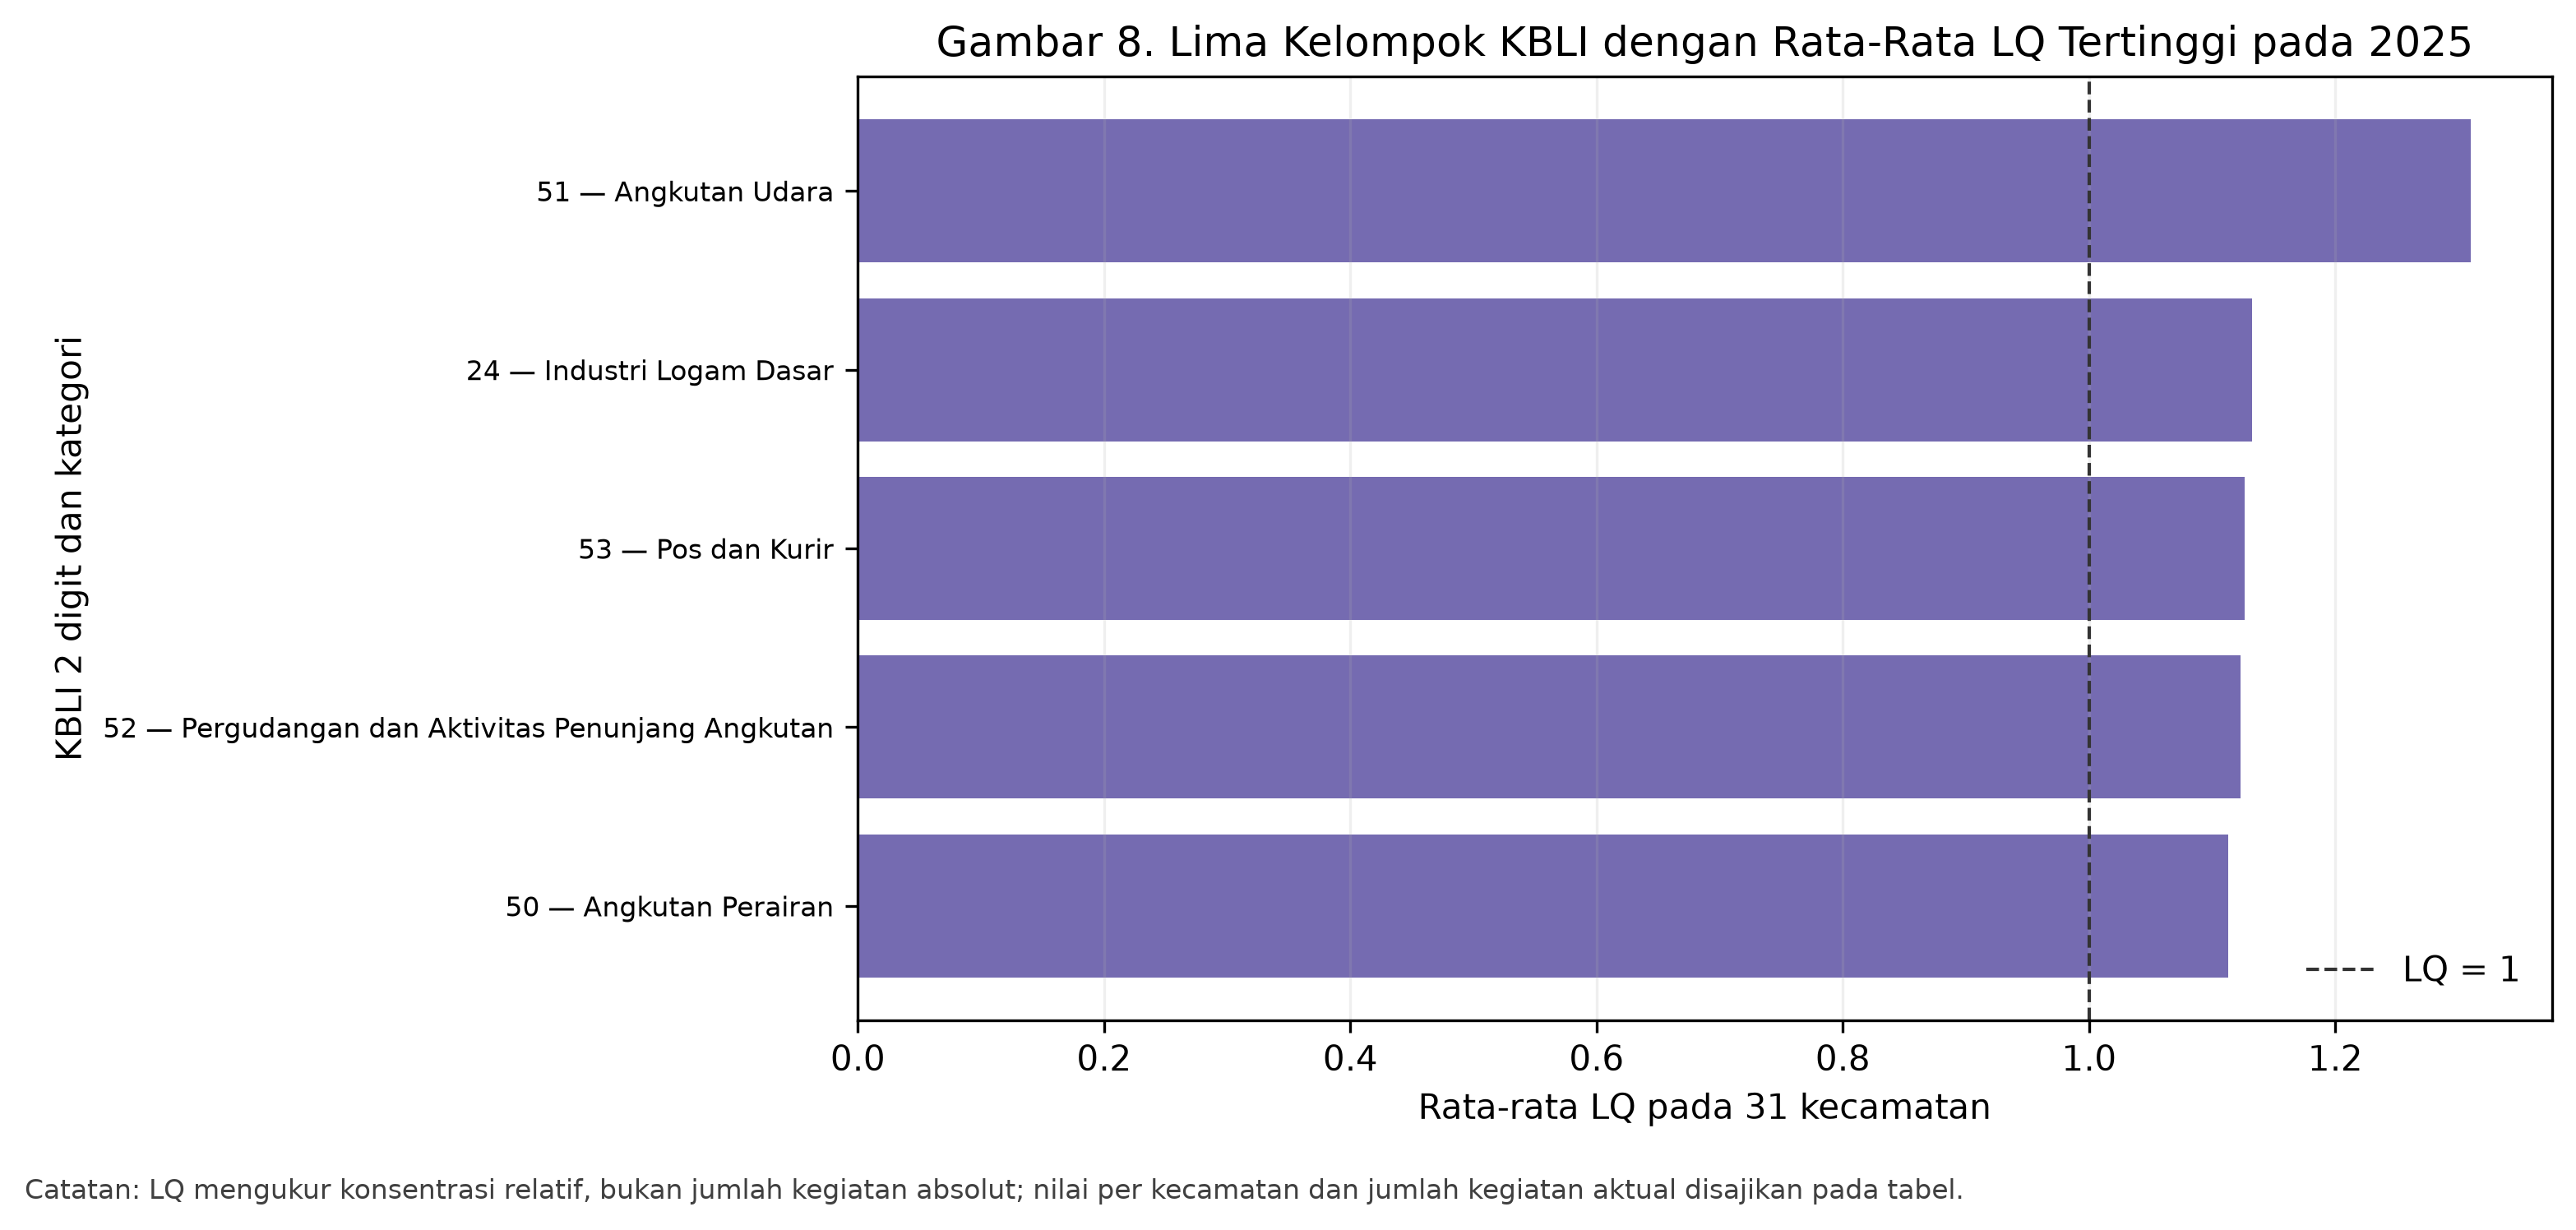

#### Gambar 9. Perubahan rerata LQ selama periode pengamatan

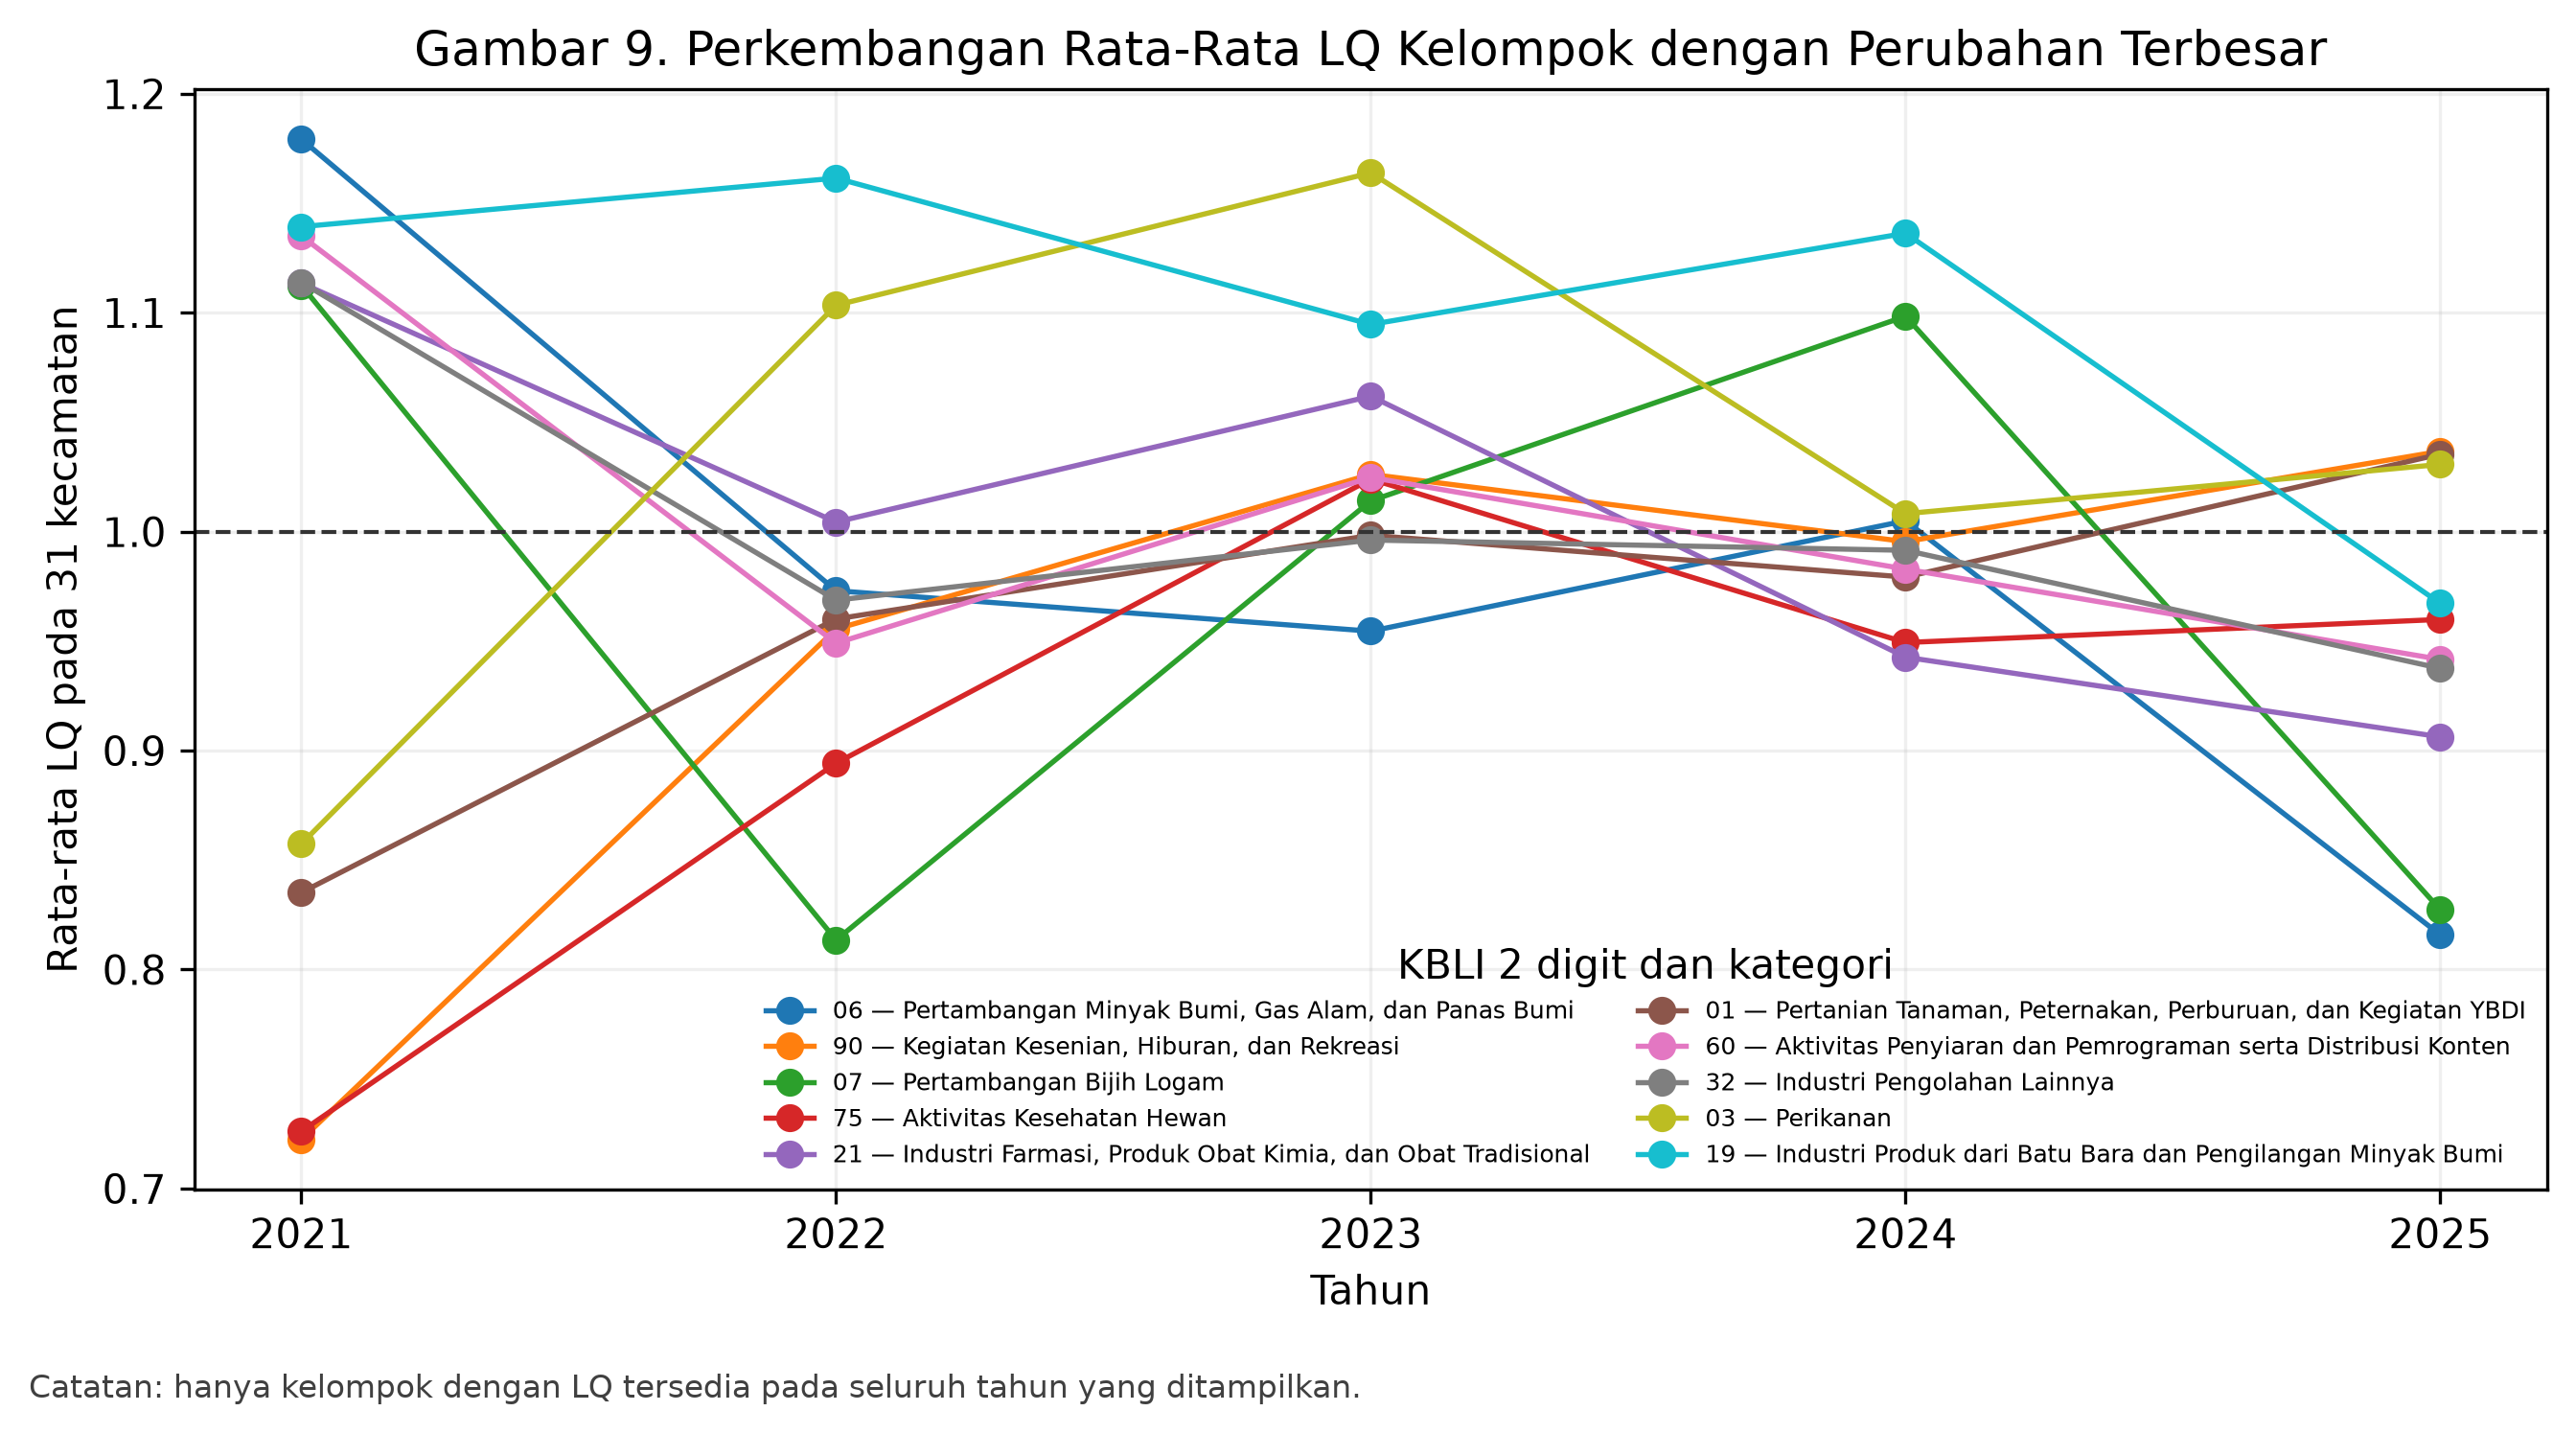

KBLI 52 (Pergudangan dan Aktivitas Penunjang Angkutan) dipilih sebagai contoh sektor yang stabil: rerata LQ sektornya di atas 1 pada kelima tahun dan jumlah kegiatan kota mencapai 1.569 pada 2025. Tabel nilai ekstrem juga menunjukkan mengapa LQ tinggi harus dibaca bersama jumlah kegiatan aktual; contohnya, beberapa nilai tertinggi berasal dari satu sampai beberapa kegiatan.

## 7. Perbandingan sektor dan wilayah basis/non-basis

Pada 2021 terdapat 916 kombinasi basis dan 1.657 non-basis; pada 2025 masing-masing 969 dan 1.511. Angka grafik adalah jumlah kombinasi kecamatan-KBLI, bukan nilai LQ atau jumlah proyek.

### Contoh representatif: KBLI 52 di Kecamatan Asem Rowo

#### Tabel 17. LQ KBLI 52 di Asem Rowo, 2021-2025

Kode KBLI 2 digit,Nama KBLI 2 digit,Kecamatan,Tahun,Jumlah kegiatan usaha,Jumlah kegiatan sektor kota,Nilai LQ,Klasifikasi LQ
52,Pergudangan dan Aktivitas Penunjang Angkutan,Asem Rowo,2.021,53,482,"5,017",Basis (Konsentrasi Tinggi)
52,Pergudangan dan Aktivitas Penunjang Angkutan,Asem Rowo,2.022,218,1.518,"5,324",Basis (Konsentrasi Tinggi)
52,Pergudangan dan Aktivitas Penunjang Angkutan,Asem Rowo,2.023,164,1.122,"7,326",Basis (Konsentrasi Tinggi)
52,Pergudangan dan Aktivitas Penunjang Angkutan,Asem Rowo,2.024,174,1.133,"7,585",Basis (Konsentrasi Tinggi)
52,Pergudangan dan Aktivitas Penunjang Angkutan,Asem Rowo,2.025,269,1.569,"7,553",Basis (Konsentrasi Tinggi)


Pemilihan ini didasarkan pada rerata LQ sektor 1,133 dan klasifikasi basis pada seluruh tahun. Di Asem Rowo, LQ juga basis setiap tahun, dengan jumlah lokal 53 sampai 269 kegiatan; konteks jumlah ini lebih representatif daripada memilih LQ ekstrem yang hanya didukung satu kegiatan.

In [5]:
display(Markdown('### Klasifikasi jumlah kombinasi kecamatan-KBLI'))
show_table('Tabel 6. Jumlah kombinasi kecamatan-KBLI menurut kategori LQ', 'Tabel_06_jumlah_kombinasi_kategori_LQ_tahunan')
show_table('Tabel 7. Lima kelompok KBLI dengan rerata LQ tertinggi per tahun', 'Tabel_07_lima_sektor_rerata_LQ_tertinggi_tahunan')
show_table('Tabel 8. Lima kecamatan dengan LQ tertinggi untuk sektor terpilih', 'Tabel_08_lima_kecamatan_LQ_tertinggi_sektor_terpilih')
show_table('Tabel 9. Perubahan rerata LQ per kelompok KBLI', 'Tabel_09_perubahan_rerata_LQ_per_sektor')
show_table('Tabel 13. Nilai LQ tertinggi beserta jumlah kegiatan aktual', 'Tabel_13_LQ_tertinggi_dan_jumlah_kegiatan_aktual')
show_figure('Gambar 7. Jumlah kombinasi kecamatan-KBLI menurut kategori LQ', 'Gambar_07_kategori_LQ_tahunan.png')
show_figure('Gambar 8. Perbandingan rerata LQ sektor terpilih', 'Gambar_08_rerata_LQ_top5.png')
show_figure('Gambar 9. Perubahan rerata LQ selama periode pengamatan', 'Gambar_09_perubahan_rerata_LQ.png')
display(Markdown(
    'KBLI 52 (Pergudangan dan Aktivitas Penunjang Angkutan) dipilih sebagai contoh sektor yang stabil: '
    'rerata LQ sektornya di atas 1 pada kelima tahun dan jumlah kegiatan kota mencapai 1.569 pada 2025. '
    'Tabel nilai ekstrem juga menunjukkan mengapa LQ tinggi harus dibaca bersama jumlah kegiatan aktual; '
    'contohnya, beberapa nilai tertinggi berasal dari satu sampai beberapa kegiatan.'
))

display(Markdown('## 7. Perbandingan sektor dan wilayah basis/non-basis'))
basis_counts = TABLES['Tabel_06_jumlah_kombinasi_kategori_LQ_tahunan'].set_index('Tahun')
display(Markdown(
    f"Pada 2021 terdapat {format_number(basis_counts.loc[2021, 'Basis (LQ > 1)'])} kombinasi basis dan "
    f"{format_number(basis_counts.loc[2021, 'Non-basis (LQ < 1)'])} non-basis; pada 2025 masing-masing "
    f"{format_number(basis_counts.loc[2025, 'Basis (LQ > 1)'])} dan "
    f"{format_number(basis_counts.loc[2025, 'Non-basis (LQ < 1)'])}. Angka grafik adalah jumlah "
    "kombinasi kecamatan-KBLI, bukan nilai LQ atau jumlah proyek."
))

display(Markdown('### Contoh representatif: KBLI 52 di Kecamatan Asem Rowo'))
representative_lq = lq_results.loc[
    lq_results['KBLI_2digit'].eq('52') & lq_results['kecamatan_usaha'].eq('Asem Rowo')
].sort_values('Tahun').copy()
if len(representative_lq) != 5:
    raise ValueError(f'Diharapkan 5 tahun LQ untuk KBLI 52 di Asem Rowo; ditemukan {len(representative_lq)}.')
representative_lq.insert(0, 'nama_kategori_kbli_2digit', 'Pergudangan dan Aktivitas Penunjang Angkutan')
representative_lq = representative_lq.rename(columns={
    'total_kegiatan_sektor_kota_tahun': 'jumlah_kegiatan_sektor_kota_tahun'
})
show_frame(
    'Tabel 17. LQ KBLI 52 di Asem Rowo, 2021-2025',
    representative_lq[[
        'KBLI_2digit', 'nama_kategori_kbli_2digit', 'kecamatan_usaha', 'Tahun',
        'jumlah_kegiatan_usaha', 'jumlah_kegiatan_sektor_kota_tahun', 'LQ', 'Kategori_LQ'
    ]],
)
representative_lq.to_csv(OUTPUT_DIR / 'Tabel_17_LQ_KBLI52_Asem_Rowo.csv', index=False)
sector_52_lq = TABLES['Tabel_09_perubahan_rerata_LQ_per_sektor'].loc[
    TABLES['Tabel_09_perubahan_rerata_LQ_per_sektor']['KBLI_2digit'].eq('52')
].iloc[0]
if not (sector_52_lq[['2021', '2022', '2023', '2024', '2025']] > 1).all():
    raise AssertionError('KBLI 52 tidak lagi konsisten basis pada lima tahun.')
display(Markdown(
    f"Pemilihan ini didasarkan pada rerata LQ sektor {format_number(sector_52_lq['rata_rata_lq_2021_2025'], 3)} "
    "dan klasifikasi basis pada seluruh tahun. Di Asem Rowo, LQ juga basis setiap tahun, dengan jumlah lokal "
    f"{format_number(representative_lq['jumlah_kegiatan_usaha'].min())} sampai "
    f"{format_number(representative_lq['jumlah_kegiatan_usaha'].max())} kegiatan; konteks jumlah ini "
    "lebih representatif daripada memilih LQ ekstrem yang hanya didukung satu kegiatan."
))

## 8. Analisis spasial pertumbuhan dan konsentrasi kegiatan usaha

Peta berikut menggunakan batas 31 kecamatan yang sudah dicocokkan dengan data melalui normalisasi nama. Peta LQ menyediakan filter tahun dan KBLI bernama; peta pertumbuhan menyediakan filter tahun dan menandai 2021 sebagai baseline. PNG pertumbuhan memakai 2022 sebagai contoh agar gradasi terlihat, sedangkan peta LQ menampilkan KBLI 52 tahun 2025. Jika peta interaktif tidak tampil dalam tampilan notebook, buka berkas HTML pada `output_jurnal` di browser.

#### Peta 1. LQ kegiatan usaha per kecamatan

#### Gambar 11. Peta LQ KBLI 52 per kecamatan, 2025

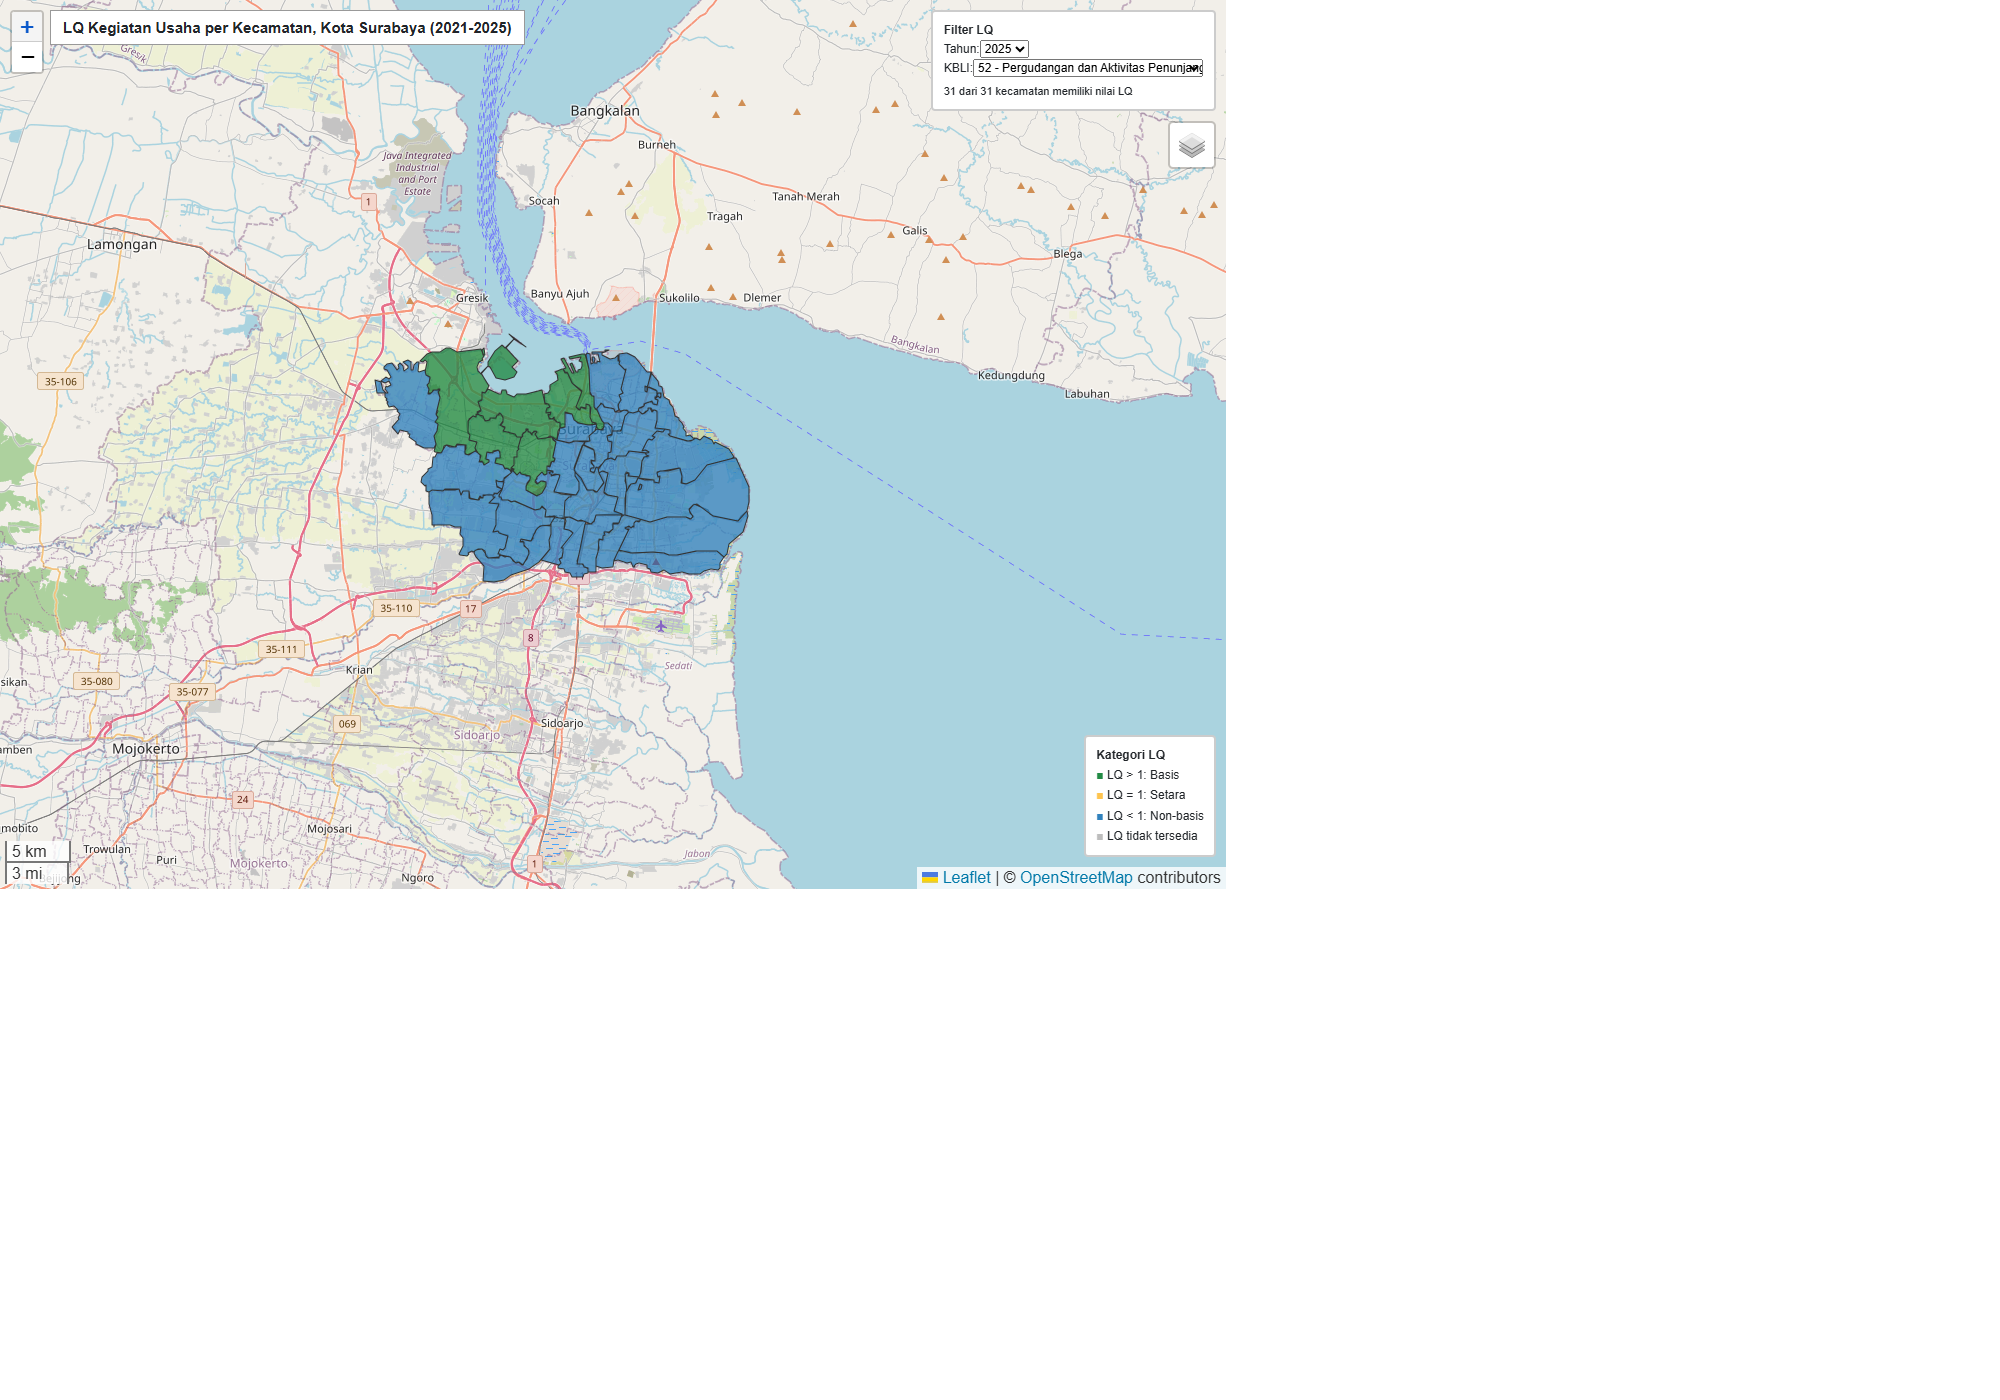

#### Peta 2. Pertumbuhan YoY kegiatan usaha per kecamatan

#### Gambar 12. Peta pertumbuhan YoY per kecamatan, 2022

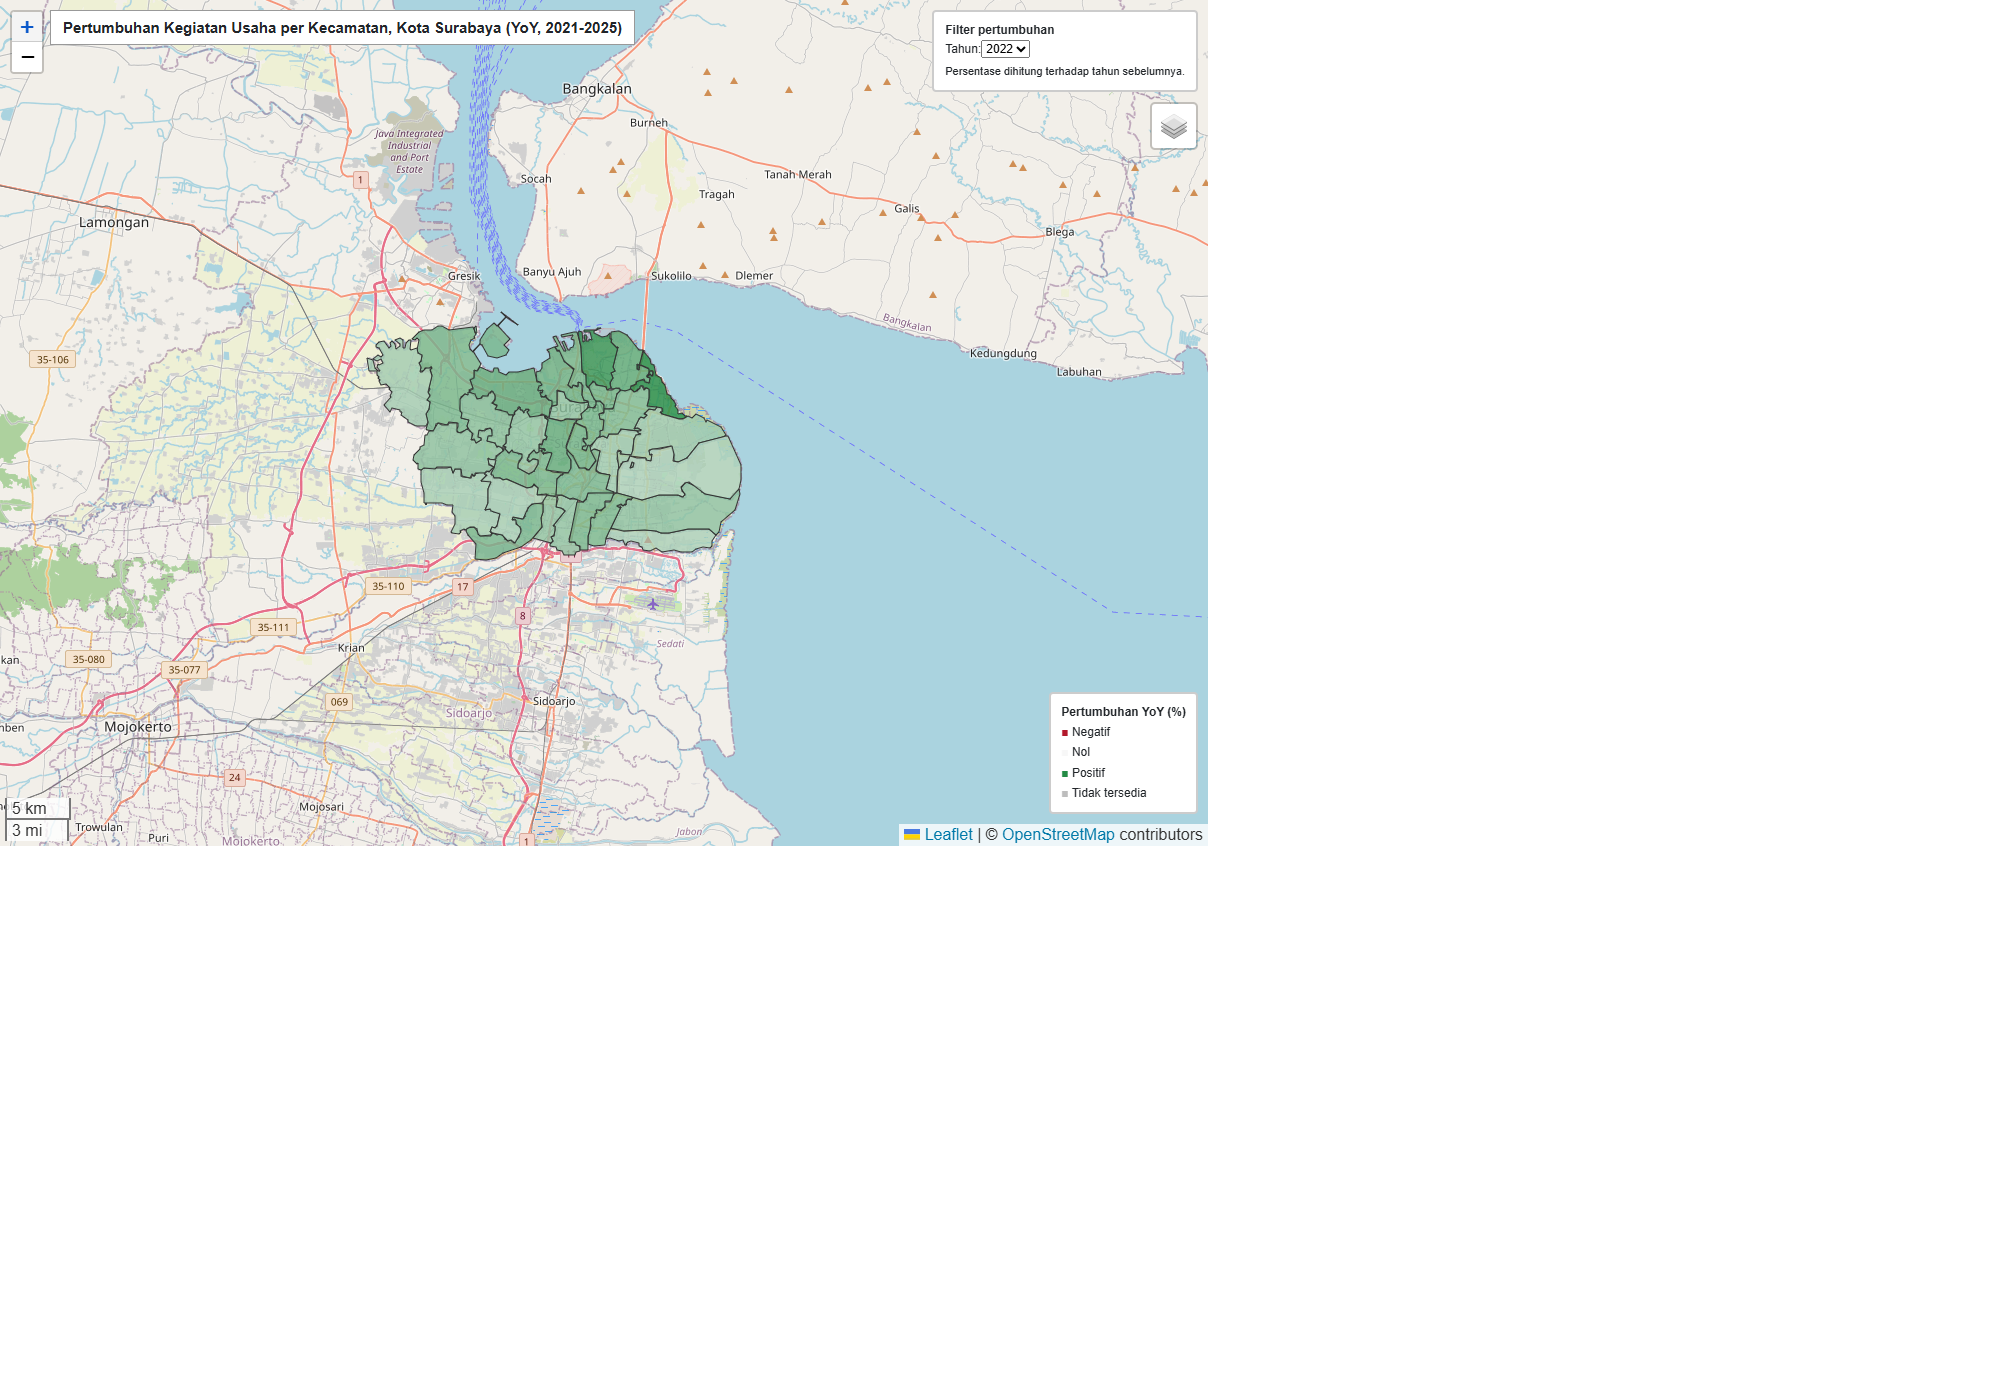

In [6]:
show_map('Peta 1. LQ kegiatan usaha per kecamatan', 'Peta_01_LQ_interaktif.html')
show_map_png('Gambar 11. Peta LQ KBLI 52 per kecamatan, 2025', 'Peta_LQ_KBLI52_2025.png')
show_map('Peta 2. Pertumbuhan YoY kegiatan usaha per kecamatan', 'Peta_02_pertumbuhan_interaktif.html')
show_map_png('Gambar 12. Peta pertumbuhan YoY per kecamatan, 2022', 'Peta_Pertumbuhan_2022.png')

## 9. Analisis gabungan LQ dan CAGR

Klasifikasi menggunakan rata-rata LQ periode 2021-2025 dan CAGR jumlah kegiatan sektoral dari 2021 ke 2025, yaitu empat interval tahunan. Rata-rata LQ memberi bobot yang sama pada kecamatan dan tahun. Analisis ini menggunakan LQ dan CAGR, bukan DLQ; sektor dengan data tidak memadai tidak dimasukkan ke empat kategori utama.

#### Tabel 10. Klasifikasi gabungan seluruh kelompok KBLI

Kode KBLI 2 digit,Nama KBLI 2 digit,2021,2025,Perubahan kumulatif 2021-2025,Perubahan kumulatif (%),CAGR 2021-2025 (%),Tahun LQ tersedia,Rerata LQ 2021-2025,status_lq,kategori_konsentrasi,Kategori gabungan,metode_pertumbuhan,metode_lq
01,"Pertanian Tanaman, Peternakan, Perburuan, dan Kegiatan YBDI",529,775,246,"46,50","10,02",5,"0,962",Lengkap,Sektor Non-Basis,Sektor Non-Basis tetapi Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
02,Kehutanan dan Penebangan Kayu,26,53,27,"103,85","19,49",5,"1,017",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
03,Perikanan,90,293,203,"225,56","34,32",5,"1,033",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
05,Pertambangan Batu Bara dan Lignit,10,9,-1,"-10,00","-2,60",5,"1,025",Lengkap,Sektor Basis,Sektor Basis tetapi Tidak Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
06,"Pertambangan Minyak Bumi, Gas Alam, dan Panas Bumi",5,1,-4,"-80,00","-33,13",5,"0,986",Lengkap,Sektor Non-Basis,Sektor Non-Basis dan Tidak Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
07,Pertambangan Bijih Logam,14,13,-1,"-7,14","-1,84",5,"0,973",Lengkap,Sektor Non-Basis,Sektor Non-Basis dan Tidak Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
08,Pertambangan dan Penggalian Lainnya,21,93,72,"342,86","45,07",5,"1,021",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
09,Aktivitas Jasa Penunjang Pertambangan,22,44,22,"100,00","18,92",5,"1,001",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
10,Industri Makanan,1.437,8.588,7.151,"497,63","56,35",5,"1,014",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara
11,Industri Minuman,190,2.453,2.263,"1.191,05","89,56",5,"1,012",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara


#### Tabel 11. Jumlah kelompok KBLI pada setiap kategori gabungan

Kategori gabungan,Jumlah kelompok KBLI
Sektor Basis dan Tumbuh,33
Sektor Basis tetapi Tidak Tumbuh,2
Sektor Non-Basis tetapi Tumbuh,43
Sektor Non-Basis dan Tidak Tumbuh,2
Data Tidak Memadai,3


#### Tabel 12. Kelompok KBLI menonjol pada setiap kategori

Kode KBLI 2 digit,Nama KBLI 2 digit,2021,2025,Perubahan kumulatif 2021-2025,Perubahan kumulatif (%),CAGR 2021-2025 (%),Tahun LQ tersedia,Rerata LQ 2021-2025,status_lq,kategori_konsentrasi,Kategori gabungan,metode_pertumbuhan,metode_lq,peringkat_dalam_kategori,keterangan_pemilihan
11,Industri Minuman,190,2.453,2.263,"1.191,05","89,56",5,"1,012",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,1,Lima sektor teratas menurut CAGR dalam kategori
51,Angkutan Udara,2,13,11,"550,00","59,67",5,"1,160",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,2,Lima sektor teratas menurut CAGR dalam kategori
10,Industri Makanan,1.437,8.588,7.151,"497,63","56,35",5,"1,014",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,3,Lima sektor teratas menurut CAGR dalam kategori
50,Angkutan Perairan,48,252,204,"425,00","51,37",5,"1,086",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,4,Lima sektor teratas menurut CAGR dalam kategori
60,Aktivitas Penyiaran dan Pemrograman serta Distribusi Konten,6,31,25,"416,67","50,77",5,"1,007",Lengkap,Sektor Basis,Sektor Basis dan Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,5,Lima sektor teratas menurut CAGR dalam kategori
05,Pertambangan Batu Bara dan Lignit,10,9,-1,"-10,00","-2,60",5,"1,025",Lengkap,Sektor Basis,Sektor Basis tetapi Tidak Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,1,Lima sektor teratas menurut CAGR dalam kategori
21,"Industri Farmasi, Produk Obat Kimia, dan Obat Tradisional",70,60,-10,"-14,29","-3,78",5,"1,006",Lengkap,Sektor Basis,Sektor Basis tetapi Tidak Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,2,Lima sektor teratas menurut CAGR dalam kategori
07,Pertambangan Bijih Logam,14,13,-1,"-7,14","-1,84",5,"0,973",Lengkap,Sektor Non-Basis,Sektor Non-Basis dan Tidak Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,1,Lima sektor teratas menurut CAGR dalam kategori
06,"Pertambangan Minyak Bumi, Gas Alam, dan Panas Bumi",5,1,-4,"-80,00","-33,13",5,"0,986",Lengkap,Sektor Non-Basis,Sektor Non-Basis dan Tidak Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,2,Lima sektor teratas menurut CAGR dalam kategori
55,Penyediaan Akomodasi,216,2.251,2.035,"942,13","79,67",5,"0,943",Lengkap,Sektor Non-Basis,Sektor Non-Basis tetapi Tumbuh,"CAGR jumlah proyek sektoral, 2021-2025 (4 interval)",Rata-rata LQ tahunan per kecamatan; bobot kecamatan dan tahun setara,1,Lima sektor teratas menurut CAGR dalam kategori


#### Gambar 10. Scatter plot rerata LQ dan CAGR

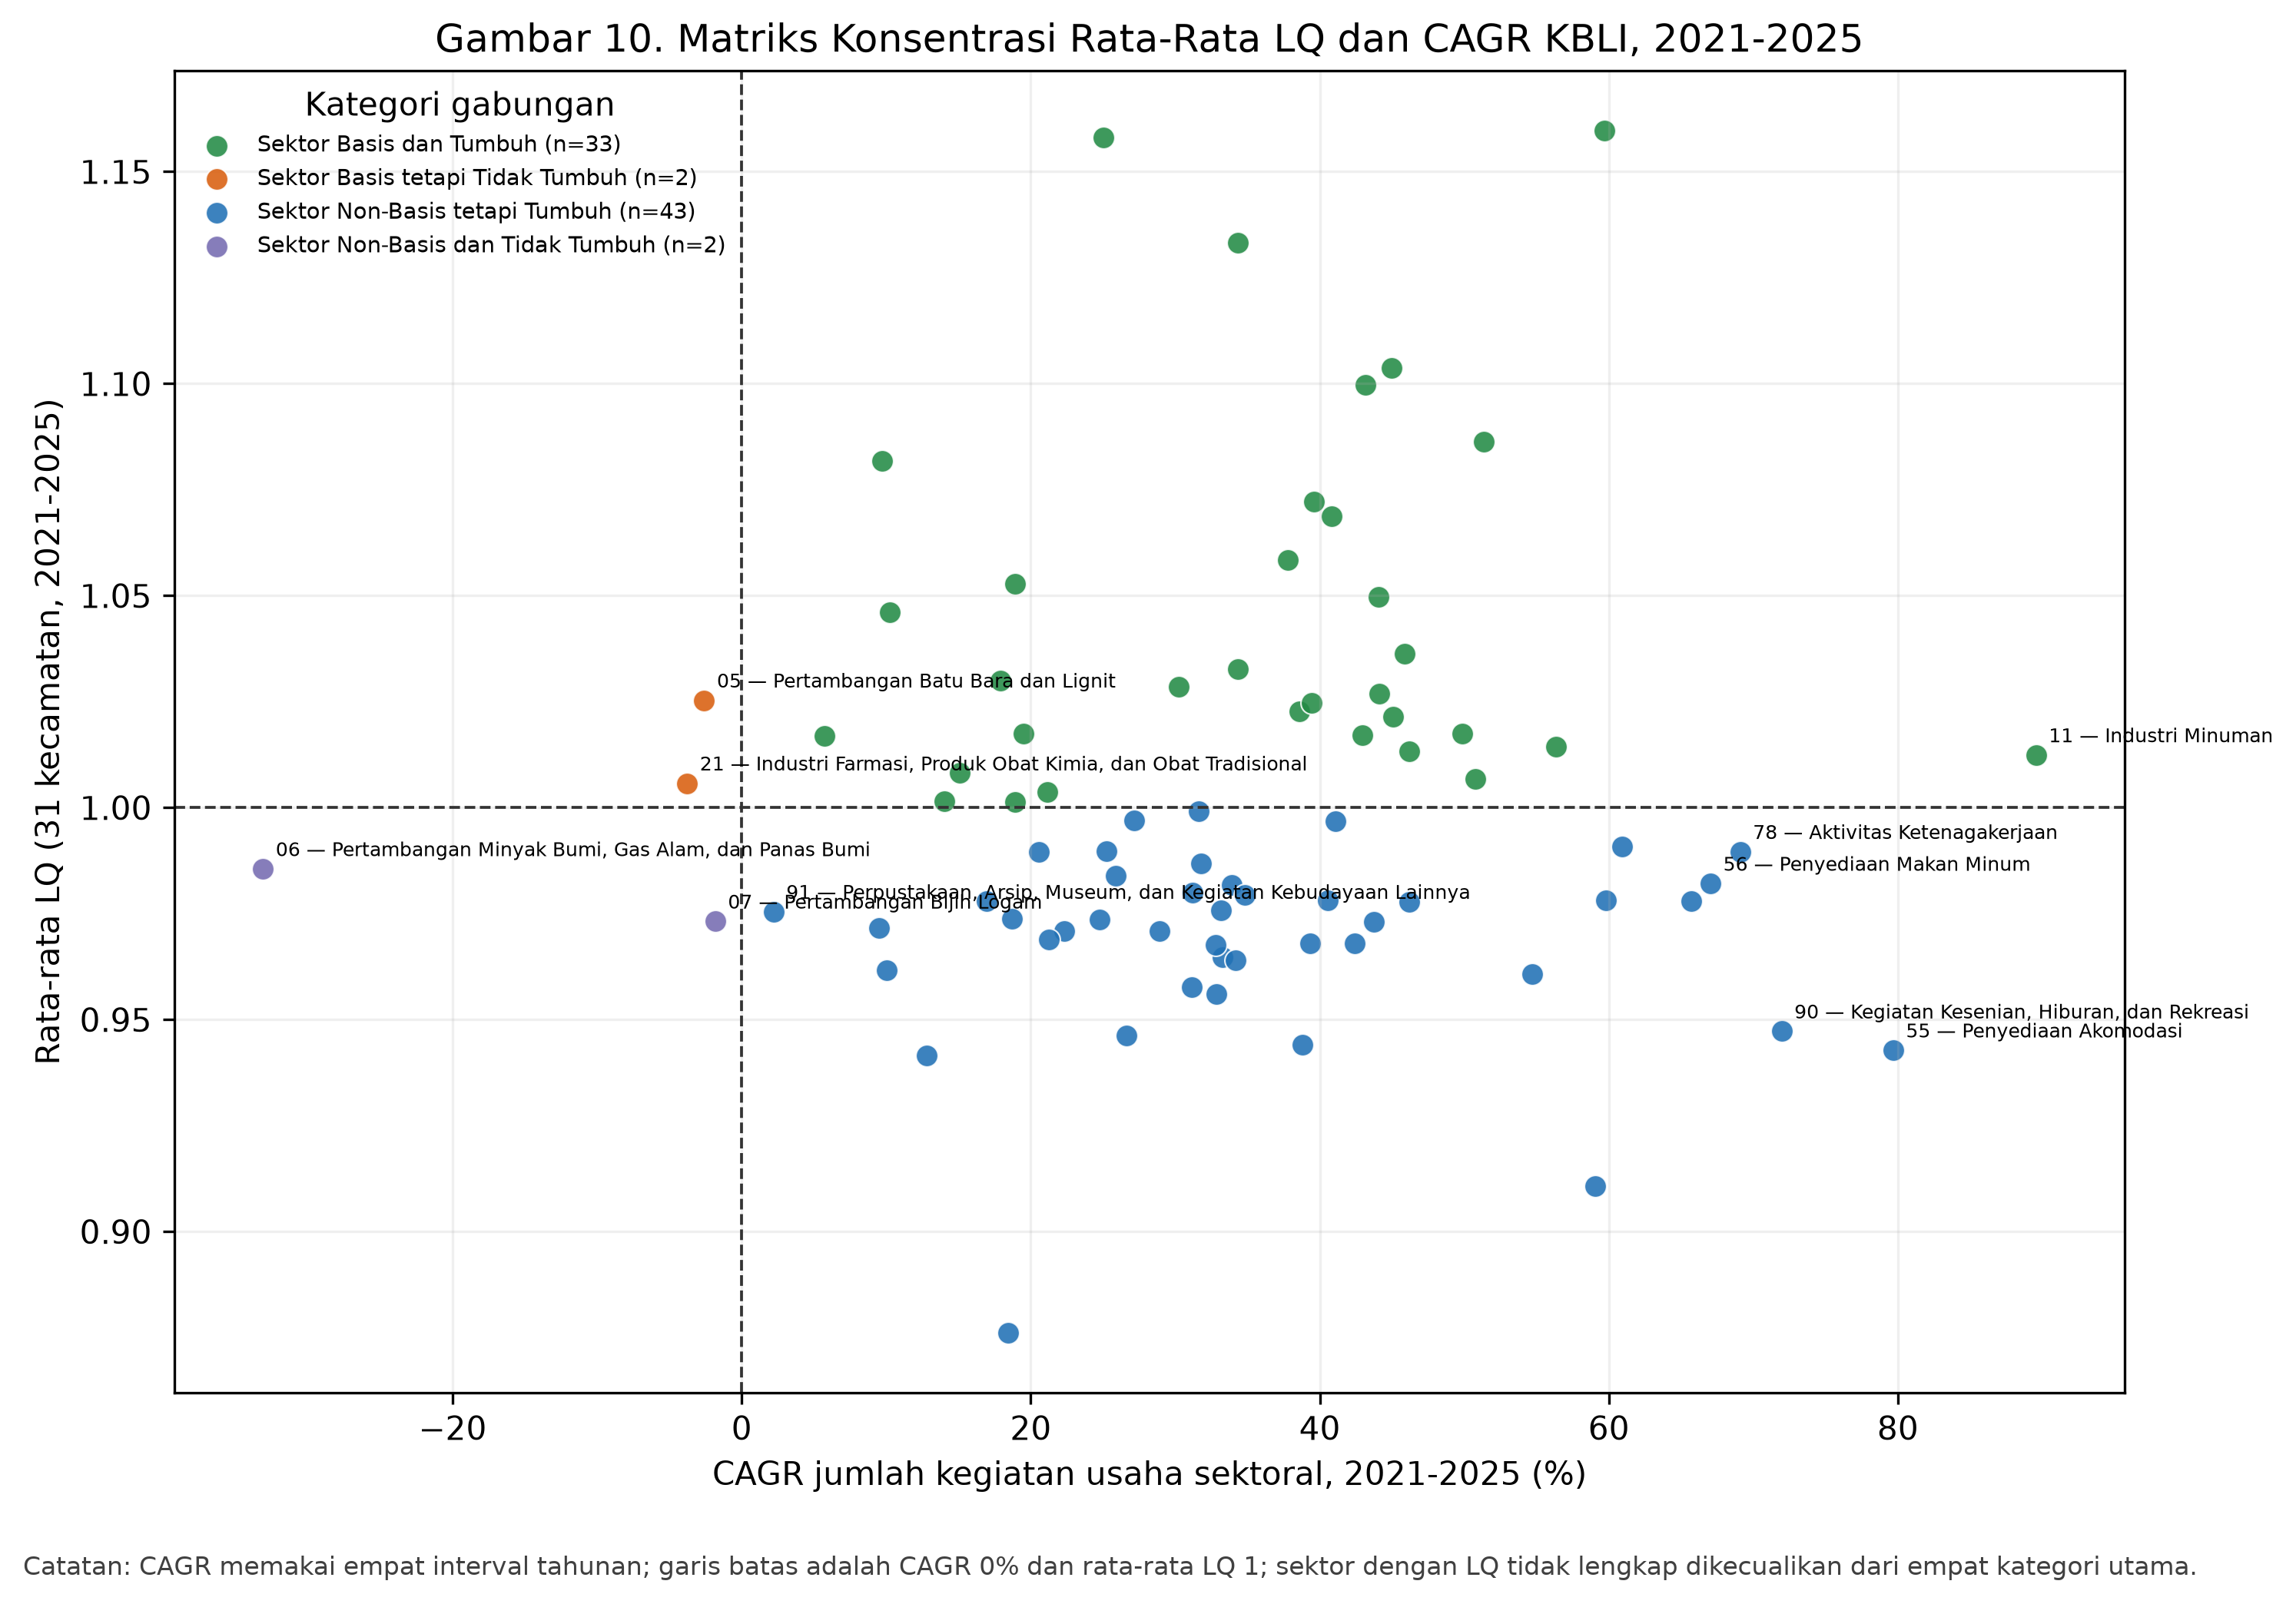

Pemeriksaan konsistensi mengonfirmasi jumlah kategori Tabel 11 sesuai dengan klasifikasi seluruh sektor pada Tabel 10. Scatter plot memakai dua ukuran tersebut: rerata LQ dan CAGR 2021-2025; kategori Data Tidak Memadai tetap terpisah dan tidak dimasukkan ke empat kategori utama.

In [7]:
show_table('Tabel 10. Klasifikasi gabungan seluruh kelompok KBLI', 'Tabel_10_analisis_gabungan_LQ_dan_CAGR')
show_table('Tabel 11. Jumlah kelompok KBLI pada setiap kategori gabungan', 'Tabel_11_ringkasan_kategori_gabungan')
show_table('Tabel 12. Kelompok KBLI menonjol pada setiap kategori', 'Tabel_12_sektor_menonjol_per_kategori')
show_figure('Gambar 10. Scatter plot rerata LQ dan CAGR', 'Gambar_10_scatter_LQ_CAGR.png')
combined = TABLES['Tabel_10_analisis_gabungan_LQ_dan_CAGR']
reported_categories = TABLES['Tabel_11_ringkasan_kategori_gabungan'].set_index('kategori_gabungan')['jumlah_kelompok_kbli']
observed_categories = combined.groupby('kategori_gabungan').size()
observed_categories.name = 'jumlah_kelompok_kbli'
if not observed_categories.sort_index().equals(reported_categories.reindex(observed_categories.index).sort_index()):
    raise AssertionError('Klasifikasi pada Tabel 10 tidak cocok dengan ringkasan kategori Tabel 11.')
display(Markdown(
    'Pemeriksaan konsistensi mengonfirmasi jumlah kategori Tabel 11 sesuai dengan klasifikasi seluruh sektor pada Tabel 10. '
    'Scatter plot memakai dua ukuran tersebut: rerata LQ dan CAGR 2021-2025; kategori Data Tidak Memadai tetap terpisah '
    'dan tidak dimasukkan ke empat kategori utama.'
))

## 10. Ringkasan hasil dan pembahasan

Ringkasan berikut disusun dari hasil tabel dan grafik final. Interpretasi menunjukkan pola asosiasi deskriptif; hasil tidak mengukur sebab-akibat, produktivitas, nilai investasi, atau kesempatan kerja.

In [8]:
summary_path = OUTPUT_DIR / 'Ringkasan_temuan_utama.md'
if not summary_path.is_file():
    raise FileNotFoundError(f'Ringkasan temuan tidak ditemukan: {summary_path}')
display(Markdown(summary_path.read_text(encoding='utf-8')))
show_table('Daftar tabel untuk naskah jurnal', 'Daftar_tabel_jurnal')
show_table('Daftar visualisasi untuk naskah jurnal', 'Daftar_visualisasi_jurnal')

# Ringkasan Temuan Utama untuk Hasil dan Pembahasan

## Dasar penghitungan

Seluruh tabel pertumbuhan dan jumlah kota menggunakan dataset cleaning `output/data_clean.csv` tanpa mengulang proses cleaning. Unit jumlah kota adalah `Id Proyek` unik di dalam tiap tahun. Satu ID yang tercatat pada lebih dari satu tahun tetap dihitung pada setiap tahun terkait; jumlah lintas tahun karena itu merupakan proyek-tahun, bukan jumlah proyek unik sepanjang periode. Agregat sektor/kecamatan juga dapat menghitung proyek yang memiliki beberapa KBLI atau lokasi.

## Temuan deskriptif dan pertumbuhan

- Jumlah `Id Proyek` unik kota: 2021: 30.252, 2022: 114.972, 2023: 129.053, 2024: 137.449, 2025: 108.324.
- Sebanyak 24 `Id Proyek` tercatat pada lebih dari satu tahun; angka tahunan menghitungnya sekali di setiap tahun kemunculannya. Ada 520,026 ID unik pada seluruh periode.
- Perubahan jumlah kota dari 2021 ke 2025 adalah 78,072 proyek (258.07%); jumlah proyek unik 2024 adalah 137,449, bukan hasil penjumlahan sektor-kecamatan.
- Pada 2024, agregat jumlah unik per kombinasi kecamatan-KBLI adalah 137,450, satu lebih banyak daripada total kota 137,449. Tabel 15 menunjukkan proyek dapat mengisi lebih dari satu kombinasi KBLI-kecamatan; baris berulang dalam kombinasi yang sama dipisahkan dari pengulangan lintas kategori.
- Kelompok dengan jumlah proyek-tahun tertinggi adalah KBLI 47 (Perdagangan Eceran, Bukan Mobil dan Sepeda Motor); terendah KBLI 39 (Aktivitas Remediasi dan Pengelolaan Sampah Lainnya).
- Kecamatan dengan jumlah proyek-tahun tertinggi adalah Rungkut; yang terendah Bulak.
- Pertumbuhan absolut kecamatan terbesar 2021-2025 ada di Semampir (2,704 proyek; 728.84% dari baseline). Persentase tetap perlu dibaca bersama jumlah awal dan akhir.
- YoY 2021 sengaja kosong sebagai baseline. Perubahan 2021-2025 ditampilkan terpisah sebagai kumulatif; CAGR adalah ukuran tersendiri pada analisis gabungan.

## Konsentrasi LQ

- LQ diklasifikasikan dengan LQ > 1 sebagai basis, LQ < 1 sebagai non-basis, dan LQ = 1 sebagai setara. Seluruh 31 kecamatan dan 83 kode KBLI masuk panel; kombinasi tanpa aktivitas menjadi LQ 0 bila sektor aktif di kota, sedangkan sektor tanpa aktivitas kota pada tahun itu berstatus LQ tidak tersedia.
- Tabel LQ lama hanya memuat kombinasi dengan kegiatan; tabel jurnal melengkapi kombinasi struktural nol. Pada 2024, tepat satu `Id Proyek` tercatat di dua kecamatan pada tahun yang sama (tanpa KBLI ganda), sehingga agregat LQ berbasis lokasi satu lebih besar dari hitungan unik kota. Tabel 15-16 merinci sumber selisih dan perbandingan klasifikasi.
- LQ tertinggi perlu dibaca bersama jumlah kegiatan lokal dan skala sektor kota pada Tabel 13. Konsentrasi relatif yang tinggi tidak menyatakan jumlah absolut yang besar.
- Agregat LQ menjumlahkan kombinasi kecamatan-KBLI. Satu proyek dengan beberapa KBLI dapat masuk ke lebih dari satu kombinasi; totalnya tidak boleh disamakan dengan jumlah proyek unik kota.

## Analisis gabungan dan implikasi

- Klasifikasi memakai rata-rata LQ 31 kecamatan dengan bobot kecamatan yang sama, lalu rata-rata 2021-2025 dengan bobot tahun yang sama, serta CAGR dari jumlah unik sektoral 2021 ke 2025 untuk empat interval. Analisis ini menggunakan LQ dan CAGR, bukan DLQ.
- Ringkasan kategori:
- Sektor Basis dan Tumbuh: 33 kelompok
- Sektor Basis tetapi Tidak Tumbuh: 2 kelompok
- Sektor Non-Basis tetapi Tumbuh: 43 kelompok
- Sektor Non-Basis dan Tidak Tumbuh: 2 kelompok
- Data Tidak Memadai: 3 kelompok
- Sektor menonjol untuk pendalaman:
- KBLI 11 (Industri Minuman), Sektor Basis dan Tumbuh: CAGR 89.56%, jumlah 2021 190, jumlah 2025 2,453.
- KBLI 51 (Angkutan Udara), Sektor Basis dan Tumbuh: CAGR 59.67%, jumlah 2021 2, jumlah 2025 13.
- KBLI 10 (Industri Makanan), Sektor Basis dan Tumbuh: CAGR 56.35%, jumlah 2021 1,437, jumlah 2025 8,588.
- KBLI 50 (Angkutan Perairan), Sektor Basis dan Tumbuh: CAGR 51.37%, jumlah 2021 48, jumlah 2025 252.
- KBLI 60 (Aktivitas Penyiaran dan Pemrograman serta Distribusi Konten), Sektor Basis dan Tumbuh: CAGR 50.77%, jumlah 2021 6, jumlah 2025 31.
- KBLI 05 (Pertambangan Batu Bara dan Lignit), Sektor Basis tetapi Tidak Tumbuh: CAGR -2.60%, jumlah 2021 10, jumlah 2025 9.
- KBLI 21 (Industri Farmasi, Produk Obat Kimia, dan Obat Tradisional), Sektor Basis tetapi Tidak Tumbuh: CAGR -3.78%, jumlah 2021 70, jumlah 2025 60.
- KBLI 07 (Pertambangan Bijih Logam), Sektor Non-Basis dan Tidak Tumbuh: CAGR -1.84%, jumlah 2021 14, jumlah 2025 13.
- KBLI 06 (Pertambangan Minyak Bumi, Gas Alam, dan Panas Bumi), Sektor Non-Basis dan Tidak Tumbuh: CAGR -33.13%, jumlah 2021 5, jumlah 2025 1.
- KBLI 55 (Penyediaan Akomodasi), Sektor Non-Basis tetapi Tumbuh: CAGR 79.67%, jumlah 2021 216, jumlah 2025 2,251.
- KBLI 90 (Kegiatan Kesenian, Hiburan, dan Rekreasi), Sektor Non-Basis tetapi Tumbuh: CAGR 71.95%, jumlah 2021 31, jumlah 2025 271.
- KBLI 78 (Aktivitas Ketenagakerjaan), Sektor Non-Basis tetapi Tumbuh: CAGR 69.08%, jumlah 2021 179, jumlah 2025 1,463.
- Hasil dapat digunakan sebagai informasi awal untuk menelaah sektor yang terkonsentrasi dan tumbuh serta perbedaan antarwilayah. Analisis ini tidak mengukur nilai investasi, produktivitas, kesempatan kerja, atau penyebab perubahan; penetapan program/perencanaan perlu dipadukan dengan indikator dan validasi lapangan yang relevan.

## Pemeriksaan yang masih memerlukan tinjauan manual

- Pastikan kembali padanan nama resmi setiap KBLI terhadap nomenklatur KBLI 2020 yang dipakai dalam artikel dan cantumkan rujukannya.
- Pemeriksaan visual browser untuk tile, batas 31 kecamatan, filter, legenda, dan data peta telah lulus; tinjau kembali ukuran/penempatan peta pada layout artikel.
- Verifikasi interpretasi substantif dan batasan data bersama penulis/ahli sektor; hasil statistik tidak mengidentifikasi hubungan sebab-akibat.


#### Daftar tabel untuk naskah jurnal

nomor,judul_yang_direkomendasikan,file,format
Tabel 1,Jumlah kegiatan usaha unik per tahun Kota Surabaya,Tabel_01_jumlah_kegiatan_tahunan_kota.csv,CSV
Tabel 2,Lima kelompok KBLI tertinggi dan terendah berdasarkan jumlah proyek-tahun,Tabel_02_ringkasan_lima_sektor_tertinggi_terendah.csv,CSV
Tabel 3,Lima kecamatan tertinggi dan terendah berdasarkan jumlah proyek-tahun,Tabel_03_ringkasan_lima_kecamatan_tertinggi_terendah.csv,CSV
Tabel 4,"Pertumbuhan kegiatan usaha sektoral KBLI 2 digit, YoY dan kumulatif",Tabel_04_pertumbuhan_kegiatan_sektor.csv,CSV
Tabel 5,"Pertumbuhan kegiatan usaha pada 31 kecamatan, YoY dan kumulatif",Tabel_05_pertumbuhan_kegiatan_kecamatan.csv,CSV
Tabel 6,Jumlah kombinasi kecamatan-KBLI menurut kategori LQ per tahun,Tabel_06_jumlah_kombinasi_kategori_LQ_tahunan.csv,CSV
Tabel 7,Lima kelompok KBLI dengan rata-rata LQ tertinggi pada setiap tahun,Tabel_07_lima_sektor_rerata_LQ_tertinggi_tahunan.csv,CSV
Tabel 8,Lima kecamatan dengan LQ tertinggi untuk lima KBLI terpilih pada 2025,Tabel_08_lima_kecamatan_LQ_tertinggi_sektor_terpilih.csv,CSV
Tabel 9,Perubahan rata-rata LQ 2021-2025 per kelompok KBLI,Tabel_09_perubahan_rerata_LQ_per_sektor.csv,CSV
Tabel 10,Klasifikasi gabungan rata-rata LQ dan CAGR 2021-2025 seluruh KBLI,Tabel_10_analisis_gabungan_LQ_dan_CAGR.csv,CSV


#### Daftar visualisasi untuk naskah jurnal

nomor,judul_yang_direkomendasikan,file,format
Gambar 1,"Jumlah Kegiatan Usaha Unik Kota Surabaya, 2021-2025",Gambar_01_jumlah_kegiatan_tahunan.png,"PNG, 300 dpi"
Gambar 2,Lima Kelompok KBLI Tertinggi dan Terendah menurut Proyek-Tahun,Gambar_02_top_bottom_kbli.png,"PNG, 300 dpi"
Gambar 3,Lima Kecamatan Tertinggi dan Terendah menurut Proyek-Tahun,Gambar_03_top_bottom_kecamatan.png,"PNG, 300 dpi"
Gambar 4,Sepuluh Kenaikan dan Penurunan Absolut Terbesar menurut KBLI,Gambar_04_pertumbuhan_absolut_sektor.png,"PNG, 300 dpi"
Gambar 5,Perubahan Absolut Jumlah Kegiatan Usaha per Kecamatan,Gambar_05_pertumbuhan_absolut_kecamatan.png,"PNG, 300 dpi"
Gambar 6,Perkembangan Tahunan Kelompok KBLI dengan Kenaikan Absolut Terbesar,Gambar_06_tren_sektor_menonjol.png,"PNG, 300 dpi"
Gambar 7,Jumlah Kombinasi Kecamatan-KBLI menurut Kategori LQ,Gambar_07_kategori_LQ_tahunan.png,"PNG, 300 dpi"
Gambar 8,Lima Kelompok KBLI dengan Rata-Rata LQ Tertinggi pada 2025,Gambar_08_rerata_LQ_top5.png,"PNG, 300 dpi"
Gambar 9,Perkembangan Rata-Rata LQ Kelompok dengan Perubahan Terbesar,Gambar_09_perubahan_rerata_LQ.png,"PNG, 300 dpi"
Gambar 10,"Matriks Konsentrasi Rata-Rata LQ dan CAGR KBLI, 2021-2025",Gambar_10_scatter_LQ_CAGR.png,"PNG, 300 dpi"
